In [1]:
import sys
sys.path.insert(0, '/Users/lyuan13/Downloads/pca_sphere_projection/')
import pca_sphere_projection.core as pc

import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import seaborn as sns
from scipy.spatial.transform import Rotation as R
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
from statsmodels.stats.multitest import multipletests

In [2]:
###################
# Basic functions #
###################
def convert_cluster_to_time(cluster):
    if '-' in cluster:
        start, end = cluster.split('-')
        return (int(start) + int(end)) / 2  # Average time
    elif '<' in cluster:
        return int(cluster.replace('< ', '')) - 1  # Slightly less than the specified time
    elif '>' in cluster:
        return int(cluster.replace('> ', '')) + 1  # Slightly more than the specified time
    return int(cluster)  # Direct conversion if no special character
#
def cartesian_to_spherical(x, y, z):
    longitude = np.arctan2(y, x)
    latitude = np.arcsin(z / np.sqrt(x**2 + y**2 + z**2))
    return longitude, latitude

In [3]:
data = pd.read_csv('celegan_pca.csv')
data['time'] = data['cluster'].apply(convert_cluster_to_time)

In [4]:
filtered_data = data.dropna(subset=['celltype'])
centroid_100_130 = filtered_data[filtered_data['cluster'] == '100-130'][['PC1', 'PC2', 'PC3']].mean().values
#
data = pc.align_to_north_pole(data, pcs_columns=['PC1', 'PC2', 'PC3'], cluster_column='cluster', root_node=centroid_100_130)
data = pc.apply_euler_rotation(data, pcs_columns=['PC1', 'PC2', 'PC3'], rotation_angles=[-30, 0, -50], degrees=True)

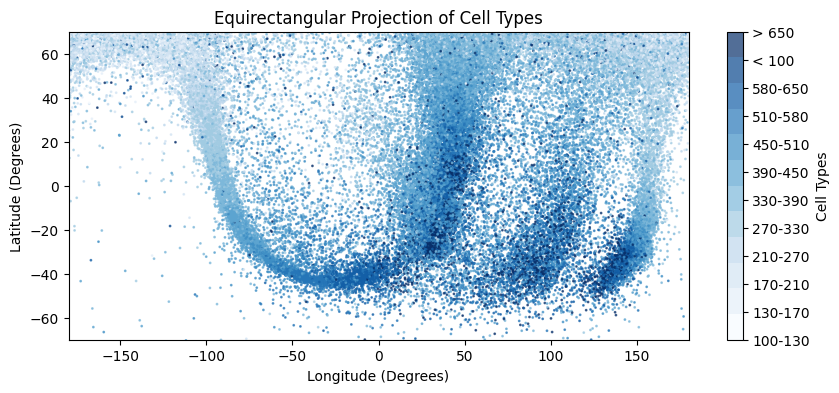

In [5]:
pc.equirectangular_projection(data, 
                              pcs_columns=['rotated_PC1', 'rotated_PC2', 'rotated_PC3'], 
                              cluster_column='cluster', 
                              categories=None, 
                              selected_celltypes=None, 
                              colormap='Blues', 
                              figsize=(10, 4), 
                              point_size=1, 
                              alpha=0.7, 
                              xlim=(-180, 180), 
                              ylim=(-70, 70))

In [6]:
######################################
# Customized function for aesthetics #
######################################
def count_cells_within_bands_wrapped(df, longitudes, bands):
    within_band_counts = []
    between_band_counts = []
    # Calculate counts within each band
    for lon, band in zip(longitudes, bands):
        within_band = df[(df['Longitude'] >= lon - band) & (df['Longitude'] <= lon + band)]
        within_band_counts.append(len(within_band))
    # Calculate counts between the bands 
    sorted_longitudes = sorted(zip(longitudes, bands), key=lambda x: x[0])  
    between_band_counts.append(df[(df['Longitude'] >= -180) & (df['Longitude'] < sorted_longitudes[0][0] - sorted_longitudes[0][1])].count()[0])
    for i in range(len(sorted_longitudes) - 1):
        end_current_band = sorted_longitudes[i][0] + sorted_longitudes[i][1]
        start_next_band = sorted_longitudes[i + 1][0] - sorted_longitudes[i + 1][1]
        between_band = df[(df['Longitude'] > end_current_band) & (df['Longitude'] < start_next_band)]
        between_band_counts.append(len(between_band))
    between_band_counts.append(df[(df['Longitude'] > sorted_longitudes[-1][0] + sorted_longitudes[-1][1]) & (df['Longitude'] <= 180)].count()[0])
    
    return within_band_counts, between_band_counts
#
def plot_stripes_and_annotate(ax, cap_data, stripe_info, counts, total_cells, cap_name):
    for name, info in stripe_info.items():
        # Polar plot
        longitude_rad = np.radians(info['longitude'])
        band_rad = np.radians(info['band'])
        # 
        ax.fill_betweenx([0, 90], longitude_rad - band_rad, longitude_rad + band_rad, color='grey', alpha=0.9)
        # 
        ax.annotate(f'{name} ({counts[name]} cells)', xy=(longitude_rad, 45), ha='center',
                    va='center', color='darkred', fontsize=10)
    #
    cap_r = 90 - np.abs(cap_data['Latitude'])
    cap_theta = np.radians(cap_data['Longitude'])
    ax.scatter(cap_theta, cap_r, c=cap_data['cluster'].astype('category').cat.codes, cmap=custom_cmap, s=5, alpha=0.3)
    ax.set_ylim(0, 90 - 50)  
    ax.set_title(f'{cap_name} Cap - Total Cells: {total_cells}')
#
def count_cells_in_stripes(df, stripes_info):
    counts = {key: 0 for key in stripes_info}
    for key, info in stripes_info.items():
        #
        lower_bound = info['longitude'] - info['band']
        upper_bound = info['longitude'] + info['band']
        #
        counts[key] = df[(df['Longitude'] >= lower_bound) & (df['Longitude'] <= upper_bound)].shape[0]
    return counts

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


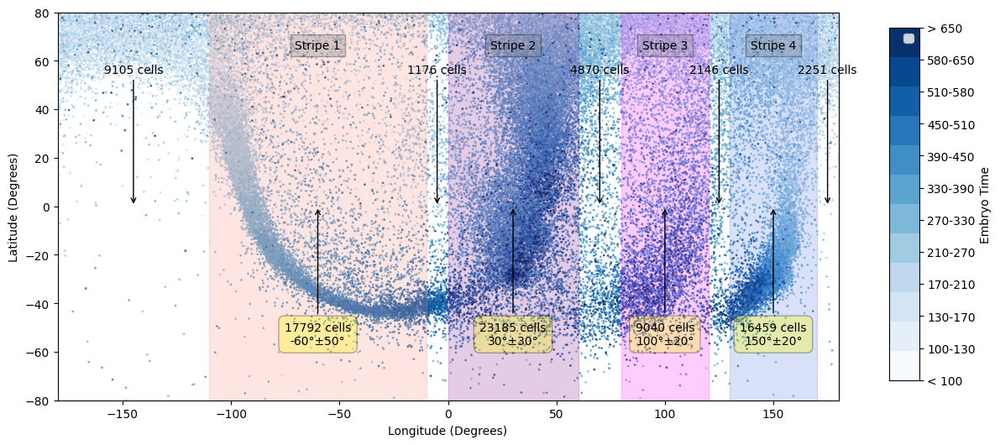

In [7]:
longitudes, latitudes = cartesian_to_spherical(data['rotated_PC1'], data['rotated_PC2'], data['rotated_PC3'])
longitudes = np.degrees(longitudes)
latitudes = np.degrees(latitudes)

data['Longitude'] = longitudes
data['Latitude'] = latitudes

#
new_longitudes = [-60, 30, 100,150]
new_bands = [50, 30, 20, 20]
    
categories = ['< 100', "100-130", "130-170", "170-210", "210-270", "270-330", "330-390", 
              "390-450", "450-510", '510-580', '580-650', '> 650' ]
color_ramp = plt.cm.get_cmap('Blues')  
custom_palette = color_ramp(np.linspace(0, 1, len(categories)))
category_codes = data['cluster'].astype('category').cat.codes
custom_cmap = ListedColormap(custom_palette)

within_counts, between_counts = count_cells_within_bands_wrapped(data, new_longitudes, new_bands)

fig, ax = plt.subplots(figsize=(12, 6))
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

ax.scatter(data['Longitude'], data['Latitude'], c=category_codes, cmap=custom_cmap, s=1, alpha=0.7)
ax.set_xlabel('Longitude (Degrees)')
ax.set_ylabel('Latitude (Degrees)')
ax.set_xlim(-180, 180)
ax.set_ylim(-80, 80)

for i, (lon, band, color) in enumerate(zip(new_longitudes, new_bands, ['salmon', 'purple', 'magenta', 'royalblue'])):
    ax.axvspan(lon - band, lon + band, color=color, alpha=0.2)
    ax.text(lon, 65, f'Stripe {i+1}', horizontalalignment='center', color='black', fontsize=10, bbox=dict(facecolor='grey', alpha=0.3))
    ax.annotate(f'{within_counts[i]} cells\n{lon}°±{band}°', xy=(lon, 0), xytext=(lon, -57),
                arrowprops=dict(facecolor='black', arrowstyle='->'),
                ha='center',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', edgecolor='black', alpha=0.3))

for i, count in enumerate(between_counts):
    if i == 0:  
        text_pos = -145  
    elif i == len(between_counts) - 1:  
        text_pos = 175  
    else:
        lon_prev = new_longitudes[i - 1] + new_bands[i - 1]
        lon_next = new_longitudes[i] - new_bands[i]
        text_pos = (lon_prev + lon_next) / 2
    ax.annotate(f'{count} cells', xy=(text_pos, 0), xytext=(text_pos, 55),
                arrowprops=dict(facecolor='gray', arrowstyle='->'),
                ha='center')

ax.grid(False)
plt.legend()
plt.show()

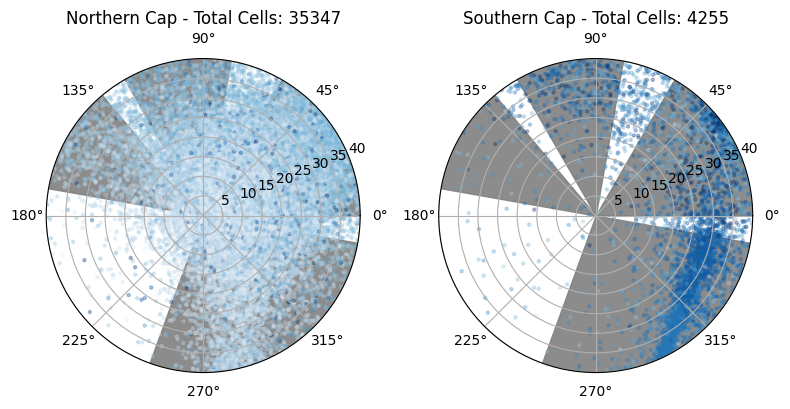

In [306]:
stripes_info = {
    'Stripe 1': {'longitude': -60, 'band': 50},
    'Stripe 2': {'longitude': 30, 'band': 30},
    'Stripe 3': {'longitude': 100, 'band': 20},
    'Stripe 4': {'longitude': 150, 'band': 20}
}

northern_cap = data[data['Latitude'] > 50]
southern_cap = data[data['Latitude'] < -50]

northern_stripe_counts = count_cells_in_stripes(northern_cap, stripes_info)
southern_stripe_counts = count_cells_in_stripes(southern_cap, stripes_info)

total_northern_cells = northern_cap.shape[0]
total_southern_cells = southern_cap.shape[0]

fig_polar, axs_polar = plt.subplots(1, 2, subplot_kw={'projection': 'polar'}, figsize=(8, 4))

plot_stripes_and_annotate(axs_polar[0], northern_cap, stripes_info, northern_stripe_counts, total_northern_cells, 'Northern') 
plot_stripes_and_annotate(axs_polar[1], southern_cap, stripes_info, southern_stripe_counts, total_southern_cells, 'Southern')

plt.tight_layout()
plt.show()

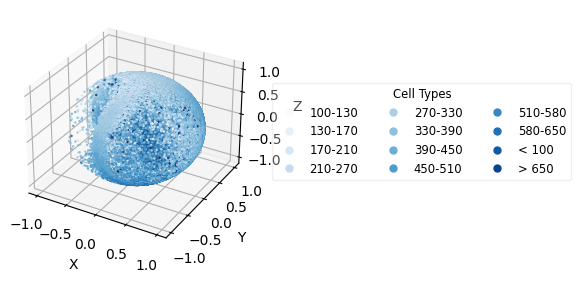

In [34]:
pc.visualize_globe( data, 
                    pcs_columns=['rotated_PC1', 'rotated_PC2', 'rotated_PC3'], 
                    cluster_column='cluster', 
                    colormap='Blues', 
                    point_size=0.5, 
                    interactive=False, 
                    output_html=None, 
                    figsize=(6, 6), 
                    legend_columns=3)

In [308]:
band_ranges = {
    'Band1': (-110, -10),
    'Band2': (0, 60),
    'Band3': (80, 120),
    'Band4': (130, 170),
    
}
data['band'] = 'Outside'

# Assign cells to the appropriate band based on their longitude
for band_name, (lower_bound, upper_bound) in band_ranges.items():
    in_band = (data['Longitude'] >= lower_bound) & (data['Longitude'] <= upper_bound)
    data.loc[in_band, 'band'] = band_name

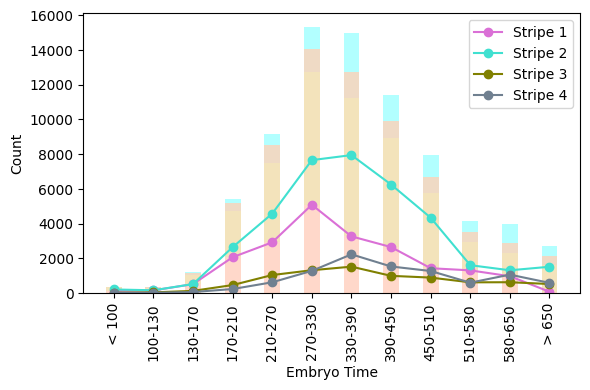

In [20]:
# Adjusting the cluster labels for sorting correctly from "<100" to ">650"
def cluster_label_adjust(cluster):
    if cluster.startswith('<'):
        return 10  # Assign a number lower than any other for '<100'
    elif cluster.startswith('>'):
        return 700  # Assign a number higher than any other for '>650'
    else:
        return int(cluster.split('-')[0])
    
#
band1_data = data[data['band'] == 'Band1']
band2_data = data[data['band'] == 'Band2']
band3_data = data[data['band'] == 'Band3']
band4_data = data[data['band'] == 'Band4']
#
band1_counts = band1_data['cluster'].value_counts().sort_index(key=lambda x: x.map(cluster_label_adjust))
band2_counts = band2_data['cluster'].value_counts().sort_index(key=lambda x: x.map(cluster_label_adjust))
band3_counts = band3_data['cluster'].value_counts().sort_index(key=lambda x: x.map(cluster_label_adjust))
band4_counts = band4_data['cluster'].value_counts().sort_index(key=lambda x: x.map(cluster_label_adjust))
# 
combined_counts = pd.DataFrame({
    'Band1': band1_counts,
    'Band2': band2_counts,
    'Band3': band3_counts,
    'Band4': band4_counts
}).fillna(0)
x_labels = combined_counts.index

# 
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(x_labels, combined_counts['Band1'], label='Stripe 1', marker='o', linestyle='-', color='orchid')
ax.plot(x_labels, combined_counts['Band2'], label='Stripe 2', marker='o', linestyle='-', color='turquoise')
ax.plot(x_labels, combined_counts['Band3'], label='Stripe 3', marker='o', linestyle='-', color='olive')
ax.plot(x_labels, combined_counts['Band4'], label='Stripe 4', marker='o', linestyle='-', color='slategrey')

ax.bar(x_labels, combined_counts['Band1'], width=0.4, alpha=0.3, color='coral')
ax.bar(x_labels, combined_counts['Band2'], bottom=combined_counts['Band1'], width=0.4, alpha=0.3, color='goldenrod')
ax.bar(x_labels, combined_counts['Band3'], bottom=combined_counts['Band1'] + combined_counts['Band2'], width=0.4, alpha=0.3, color='peru')
ax.bar(x_labels, combined_counts['Band4'], bottom=combined_counts['Band1'] + combined_counts['Band2'] + combined_counts['Band3'], width=0.4, alpha=0.3, color='aqua')

ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=90)
ax.set_xlabel('Embryo Time')
ax.set_ylabel('Count')
ax.legend()

plt.tight_layout()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_5572\4286407141.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  band1_data['cluster_numeric'] = band1_data['cluster'].apply(cluster_to_numeric)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_5572\4286407141.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  band2_data['cluster_numeric'] = band2_data['cluster'].apply(cluster_to_numeric)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_5572\4286407141.py:14: SettingWithCopyWarning: 
A value is trying to be set 

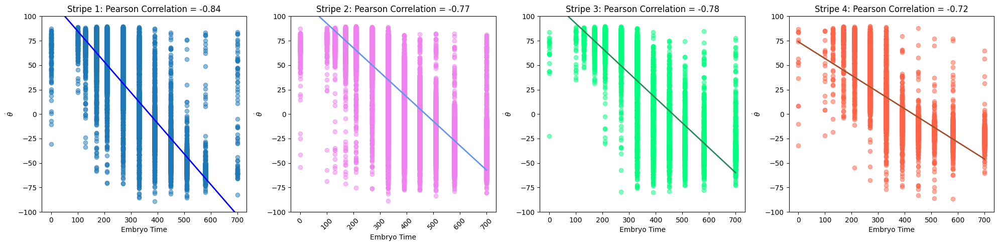

In [23]:
def cluster_to_numeric(cluster):
    if cluster.startswith('<'):
        return 0 
    elif cluster.startswith('>'):
        return 700 
    else:
        return int(cluster.split('-')[0])

#
band1_data['cluster_numeric'] = band1_data['cluster'].apply(cluster_to_numeric)
band2_data['cluster_numeric'] = band2_data['cluster'].apply(cluster_to_numeric)
band3_data['cluster_numeric'] = band3_data['cluster'].apply(cluster_to_numeric)
band4_data['cluster_numeric'] = band4_data['cluster'].apply(cluster_to_numeric)

# 
band1_data_sorted = band1_data.sort_values('cluster_numeric')
band2_data_sorted = band2_data.sort_values('cluster_numeric')
band3_data_sorted = band3_data.sort_values('cluster_numeric')
band4_data_sorted = band4_data.sort_values('cluster_numeric')

# 
clean_band1_data = band1_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band2_data = band2_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band3_data = band3_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band4_data = band4_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])

# 
model_band1 = LinearRegression().fit(clean_band1_data[['cluster_numeric']], clean_band1_data['Latitude'])
model_band2 = LinearRegression().fit(clean_band2_data[['cluster_numeric']], clean_band2_data['Latitude'])
model_band3 = LinearRegression().fit(clean_band3_data[['cluster_numeric']], clean_band3_data['Latitude'])
model_band4 = LinearRegression().fit(clean_band4_data[['cluster_numeric']], clean_band4_data['Latitude'])

# 
theta_pred_band1 = model_band1.predict(clean_band1_data[['cluster_numeric']])
theta_pred_band2 = model_band2.predict(clean_band2_data[['cluster_numeric']])
theta_pred_band3 = model_band3.predict(clean_band3_data[['cluster_numeric']])
theta_pred_band4 = model_band4.predict(clean_band4_data[['cluster_numeric']])

# 
corr_band1_clean = clean_band1_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]
corr_band2_clean = clean_band2_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]
corr_band3_clean = clean_band3_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]
corr_band4_clean = clean_band4_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]

# 
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 5))

axes[0].scatter(clean_band1_data['cluster_numeric'], clean_band1_data['Latitude'], alpha=0.5)
axes[0].plot(clean_band1_data['cluster_numeric'], theta_pred_band1, color='blue', linewidth=2)
axes[0].set_title(f'Stripe 1: Pearson Correlation = {corr_band1_clean:.2f}')
axes[0].set_xlabel('Embryo Time')
axes[0].set_ylabel(r"$\dot{\theta}$")
axes[0].set_ylim(-100, 100)

axes[1].scatter(clean_band2_data['cluster_numeric'], clean_band2_data['Latitude'], alpha=0.5, color='violet')
axes[1].plot(clean_band2_data['cluster_numeric'], theta_pred_band2, color='cornflowerblue', linewidth=2)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
axes[1].set_title(f'Stripe 2: Pearson Correlation = {corr_band2_clean:.2f}')
axes[1].set_xlabel('Embryo Time')
axes[1].set_ylabel(r"$\dot{\theta}$")
axes[1].set_ylim(-100, 100)

axes[2].scatter(clean_band3_data['cluster_numeric'], clean_band3_data['Latitude'], alpha=0.5, color='springgreen')
axes[2].plot(clean_band3_data['cluster_numeric'], theta_pred_band3, color='seagreen', linewidth=2)
axes[2].set_title(f'Stripe 3: Pearson Correlation = {corr_band3_clean:.2f}')
axes[2].set_xlabel('Embryo Time')
axes[2].set_ylabel(r"$\dot{\theta}$")
axes[2].set_ylim(-100, 100)

axes[3].scatter(clean_band4_data['cluster_numeric'], clean_band4_data['Latitude'], alpha=0.5, color='tomato')
axes[3].plot(clean_band4_data['cluster_numeric'], theta_pred_band4, color='sienna', linewidth=2)
axes[3].set_title(f'Stripe 4: Pearson Correlation = {corr_band4_clean:.2f}')
axes[3].set_xlabel('Embryo Time')
axes[3].set_ylabel(r"$\dot{\theta}$")
axes[3].set_ylim(-100, 100)

plt.tight_layout()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\3032554218.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band1_data, ax=axes[0], palette='OrRd',cut=0)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\3032554218.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band2_data, ax=axes[1], palette='GnBu', cut=0)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\3032554218.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluste

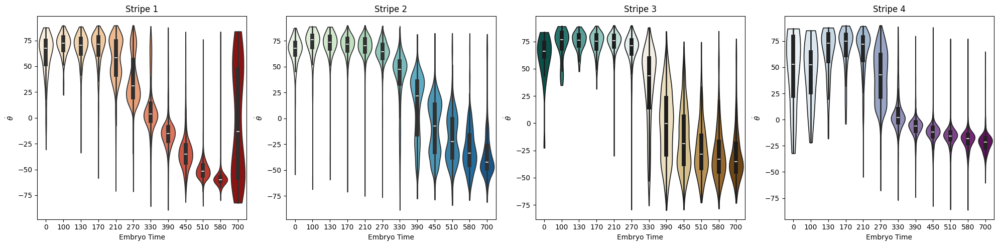

In [328]:
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 5))

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band1_data, ax=axes[0], palette='OrRd',cut=0)
axes[0].set_title(f'Stripe 1') 
axes[0].set_xlabel('Embryo Time')
axes[0].set_ylabel(r"$\dot{\theta}$")

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band2_data, ax=axes[1], palette='GnBu', cut=0)
axes[1].set_title(f'Stripe 2')
axes[1].set_xlabel('Embryo Time')
axes[1].set_ylabel(r"$\dot{\theta}$")

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band3_data, ax=axes[2], palette='BrBG_r', cut=0)
axes[2].set_title(f'Stripe 3')
axes[2].set_xlabel('Embryo Time')
axes[2].set_ylabel(r"$\dot{\theta}$")

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band4_data, ax=axes[3], palette='BuPu', cut=0)
axes[3].set_title(f'Stripe 4') 
axes[3].set_xlabel('Embryo Time')
axes[3].set_ylabel(r"$\dot{\theta}$")

plt.tight_layout()
plt.show()

In [21]:
gene = pd.read_csv('celegan_2766_gene_77060_cells.csv')
#
gene_band1 = gene[gene['Unnamed: 0'].isin(data[data['band'] == 'Band1']['Unnamed: 0'])]
gene_band2 = gene[gene['Unnamed: 0'].isin(data[data['band'] == 'Band2']['Unnamed: 0'])]
gene_band3 = gene[gene['Unnamed: 0'].isin(data[data['band'] == 'Band3']['Unnamed: 0'])]
gene_band4 = gene[gene['Unnamed: 0'].isin(data[data['band'] == 'Band4']['Unnamed: 0'])]

In [24]:
def calculate_spearman_correlation(band_data, gene_data):
    #
    aligned_data = pd.merge(band_data[['Unnamed: 0', 'cluster_numeric']], gene_data, on='Unnamed: 0')
    #
    results = []
    for gene in gene_data.columns[1:]:
        if np.var(aligned_data[gene]) < 1e-8 or np.var(aligned_data['cluster_numeric']) < 1e-8:
            #print(f"Skipping {gene} due to constant data.")
            continue  
        correlation, p_value = spearmanr(aligned_data['cluster_numeric'], aligned_data[gene])
        results.append({
            'Gene': gene,
            'Correlation': correlation,
            'P-value': p_value
        })
    #
    results_df = pd.DataFrame(results)
    results_df.dropna(inplace=True) 
    results_df.sort_values(by='Correlation', ascending=False, inplace=True)
    # 
    adjusted_pvals = multipletests(results_df['P-value'], alpha=0.05, method='fdr_bh')[1]
    results_df['Adjusted P-Value'] = adjusted_pvals
    epsilon = 1e-10
    results_df['-log10(Adjusted P-Value)'] = -np.log10(results_df['Adjusted P-Value']+ epsilon) 

    return results_df
#
band1_results = calculate_spearman_correlation(band1_data, gene_band1)
band2_results = calculate_spearman_correlation(band2_data, gene_band2)
band3_results = calculate_spearman_correlation(band3_data, gene_band3)
band4_results = calculate_spearman_correlation(band4_data, gene_band4)

## Gene Correlation

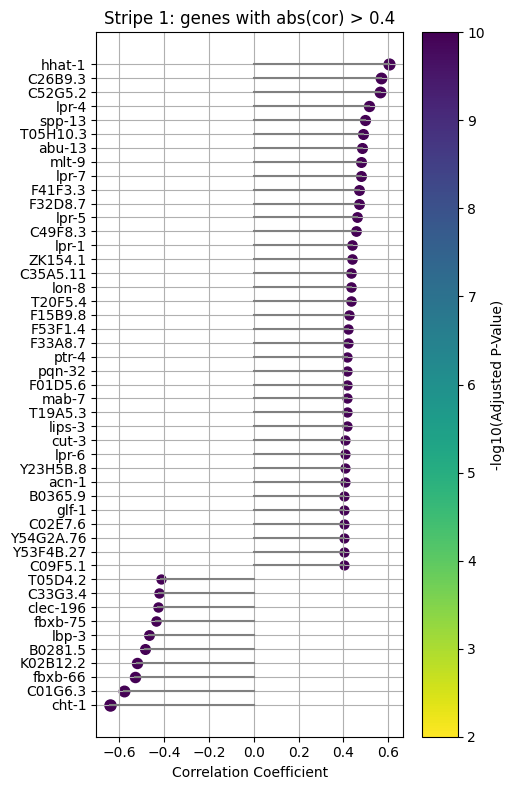

In [397]:
import matplotlib.pyplot as plt
from matplotlib.cm import viridis
from matplotlib.colors import Normalize

filtered_genes = band1_results[(band1_results['Correlation'] > 0.4) | (band1_results['Correlation'] < -0.4)]
filtered_genes = filtered_genes.sort_values(by='Correlation', ascending=True)

fig, ax = plt.subplots(figsize=(5, 8))  
norm = Normalize(vmin=2, vmax=10)
sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=norm)
sm.set_array([])

for index, (i, row) in enumerate(filtered_genes.iterrows()):
    ax.plot([0, row['Correlation']], [index, index], 'gray')  # Line for lollipop
    ax.scatter(row['Correlation'], index, color=sm.to_rgba(row['-log10(Adjusted P-Value)']), s=np.abs(row['Correlation'])*100)  

ax.set_yticks(range(len(filtered_genes)))
ax.set_yticklabels(filtered_genes['Gene'])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('-log10(Adjusted P-Value)')
cbar.ax.set_position([0.5, 0.3, 0.03, 0.4])

ax.set_xlabel('Correlation Coefficient')
ax.grid(True)
ax.set_title('Stripe 1: genes with abs(cor) > 0.4')

plt.tight_layout()
plt.show()

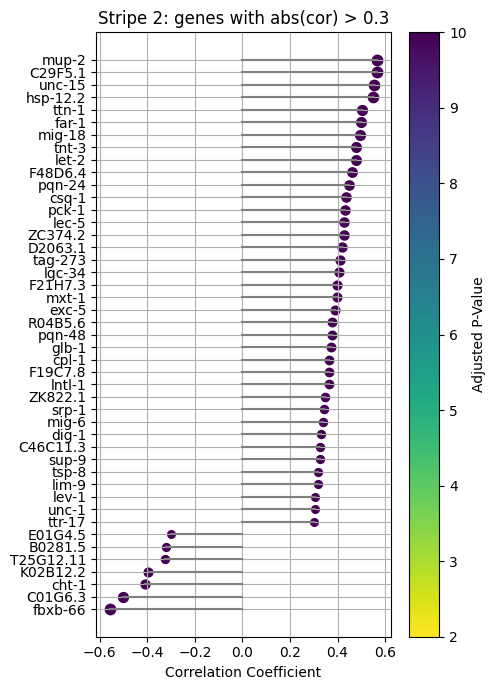

In [398]:
filtered_genes = band2_results[(band2_results['Correlation'] > 0.3) | (band2_results['Correlation'] < -0.3)]
filtered_genes = filtered_genes.sort_values(by='Correlation', ascending=True)

fig, ax = plt.subplots(figsize=(5, 7))  
norm = Normalize(vmin=2, vmax=10)
sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=norm)
sm.set_array([])

for index, (i, row) in enumerate(filtered_genes.iterrows()):
    ax.plot([0, row['Correlation']], [index, index], 'gray')  
    ax.scatter(row['Correlation'], index, color=sm.to_rgba(row['-log10(Adjusted P-Value)']), s=np.abs(row['Correlation'])*100)  

ax.set_yticks(range(len(filtered_genes)))
ax.set_yticklabels(filtered_genes['Gene'])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Adjusted P-Value')


ax.set_xlabel('Correlation Coefficient')
ax.grid(True)
ax.set_title('Stripe 2: genes with abs(cor) > 0.3')

plt.tight_layout()
plt.show()

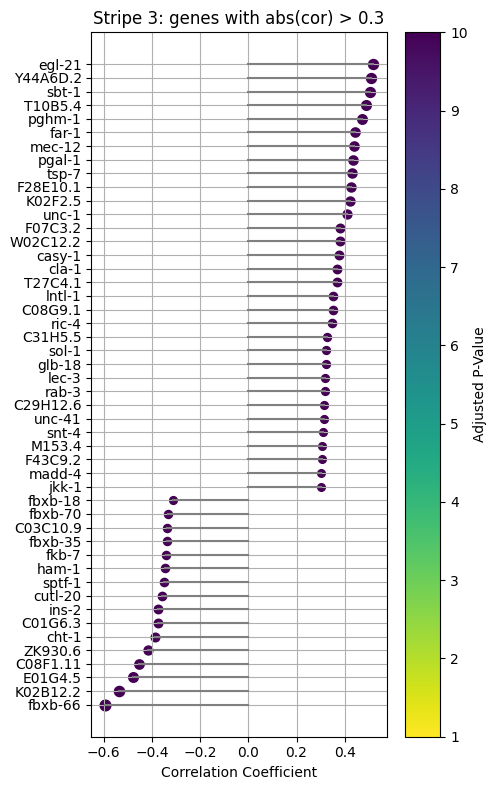

In [404]:
filtered_genes = band3_results[(band3_results['Correlation'] > 0.3) | (band3_results['Correlation'] < -0.3)]
filtered_genes = filtered_genes.sort_values(by='Correlation', ascending=True)

fig, ax = plt.subplots(figsize=(5, 8))  
norm = Normalize(vmin=1, vmax=10)
sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=norm)
sm.set_array([])

for index, (i, row) in enumerate(filtered_genes.iterrows()):
    ax.plot([0, row['Correlation']], [index, index], 'gray') 
    ax.scatter(row['Correlation'], index, color=sm.to_rgba(row['-log10(Adjusted P-Value)']), s=np.abs(row['Correlation'])*100) 

ax.set_yticks(range(len(filtered_genes)))
ax.set_yticklabels(filtered_genes['Gene'])


cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Adjusted P-Value')

ax.set_xlabel('Correlation Coefficient')
ax.grid(True)
ax.set_title('Stripe 3: genes with abs(cor) > 0.3')

plt.tight_layout()
plt.show()

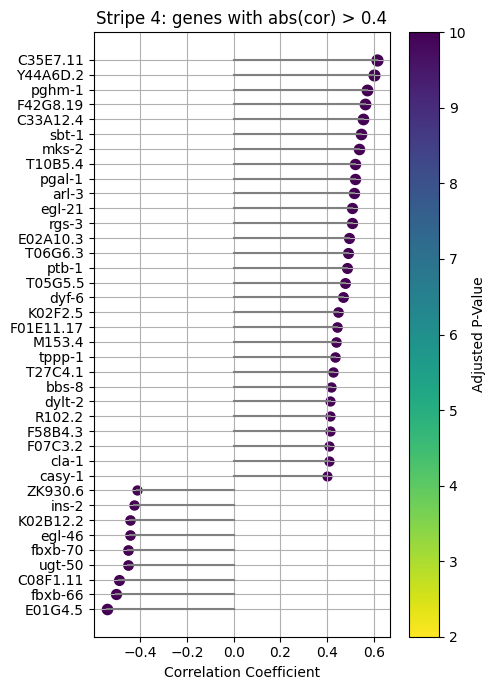

In [405]:
filtered_genes = band4_results[(band4_results['Correlation'] > 0.4) | (band4_results['Correlation'] < -0.4)]
filtered_genes = filtered_genes.sort_values(by='Correlation', ascending=True)

fig, ax = plt.subplots(figsize=(5, 7)) 

norm = Normalize(vmin=2, vmax=10)
sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=norm)
sm.set_array([])

for index, (i, row) in enumerate(filtered_genes.iterrows()):
    ax.plot([0, row['Correlation']], [index, index], 'gray')  
    ax.scatter(row['Correlation'], index, color=sm.to_rgba(row['-log10(Adjusted P-Value)']), s=np.abs(row['Correlation'])*100)  

ax.set_yticks(range(len(filtered_genes)))
ax.set_yticklabels(filtered_genes['Gene'])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Adjusted P-Value')

ax.set_xlabel('Correlation Coefficient')
ax.grid(True)
ax.set_title('Stripe 4: genes with abs(cor) > 0.4')

plt.tight_layout()
plt.show()

In [416]:
def visualize_gene_correlations(band_data, gene_data, gene_list):
    aligned_data = pd.merge(band_data[['Unnamed: 0', 'cluster_numeric']], gene_data, on='Unnamed: 0')
    aligned_data['cluster_numeric'] = aligned_data['cluster_numeric'].astype('category')

    fig, axs = plt.subplots(1, len(gene_list), figsize=(16, 4))
    if len(gene_list) == 1:
        axs = [axs]
    for ax, gene in zip(axs, gene_list):
        if gene in aligned_data.columns:
            sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Pastel2')
            ax.set_title(f'{gene}')
            ax.set_xlabel('Embryo Time')
            ax.set_ylabel(f'Expression of {gene}')
        else:
            ax.text(0.5, 0.5, f'Gene {gene} not found in data', horizontalalignment='center', verticalalignment='center')
            ax.set_xlabel('Embryo Time')
            ax.set_ylabel(f'Expression of {gene}')
    
    plt.tight_layout()
    plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1541722954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='OrRd')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1541722954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='OrRd')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1541722954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=

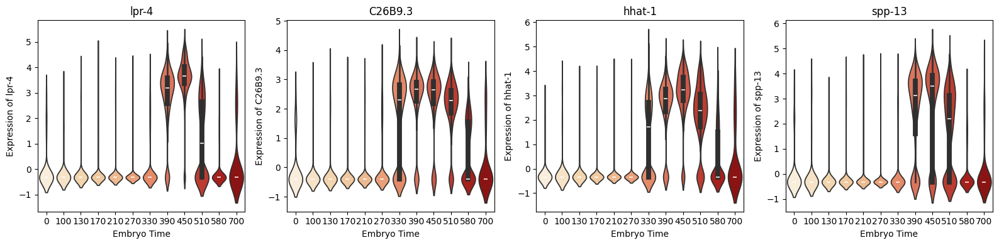

In [409]:
visualize_gene_correlations(band1_data, gene_band1, ['lpr-4','C26B9.3','hhat-1', 'spp-13'])

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1541722954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='OrRd')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1541722954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='OrRd')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1541722954.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=

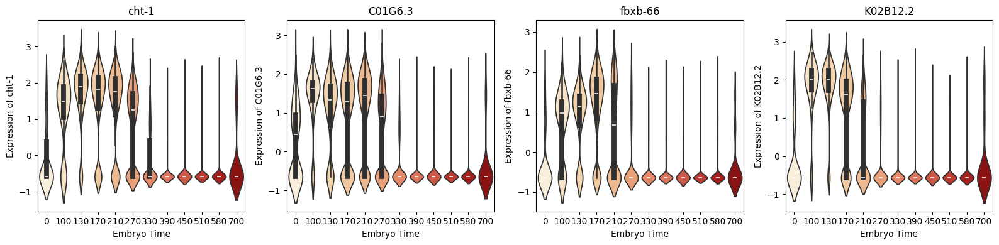

In [410]:
visualize_gene_correlations(band1_data, gene_band1, ['cht-1','C01G6.3','fbxb-66', 'K02B12.2'])

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\651433985.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Paired_r')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\651433985.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Paired_r')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\651433985.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data

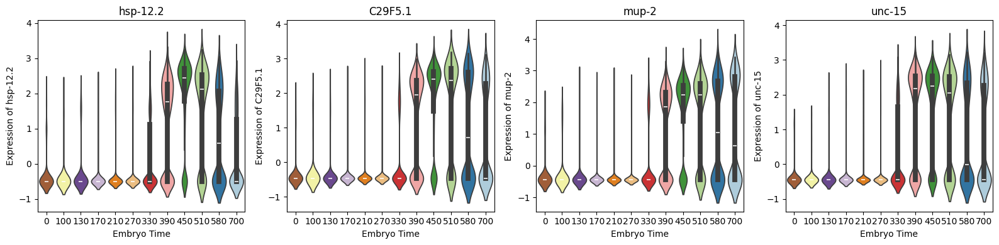

In [413]:
visualize_gene_correlations(band2_data, gene_band2, ['hsp-12.2','C29F5.1','mup-2','unc-15'])

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\4272823964.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='PuBuGn')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\4272823964.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='PuBuGn')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\4272823964.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data,

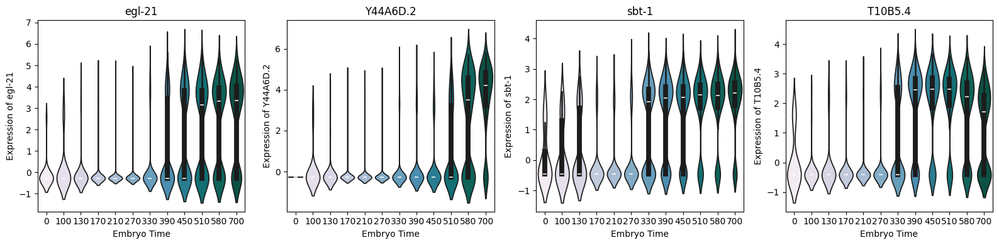

In [415]:
visualize_gene_correlations(band3_data, gene_band3, ['egl-21','Y44A6D.2','sbt-1', 'T10B5.4'])

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1469151289.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Pastel2')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1469151289.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Pastel2')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1469151289.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_dat

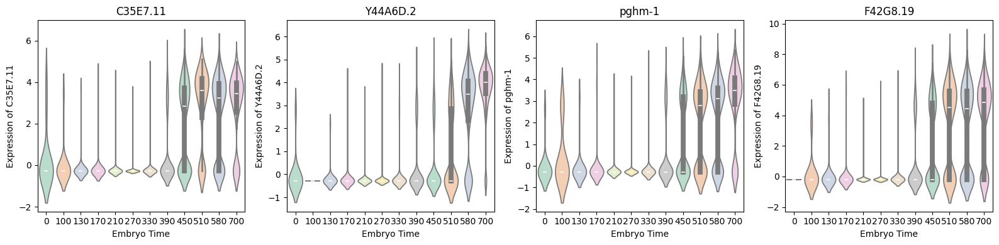

In [417]:
visualize_gene_correlations(band4_data, gene_band4, ['C35E7.11','Y44A6D.2', 'pghm-1', 'F42G8.19'])

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\2545999311.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Pastel2')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\2545999311.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax, palette='Pastel2')
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\2545999311.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster_numeric', y=gene, data=aligned_dat

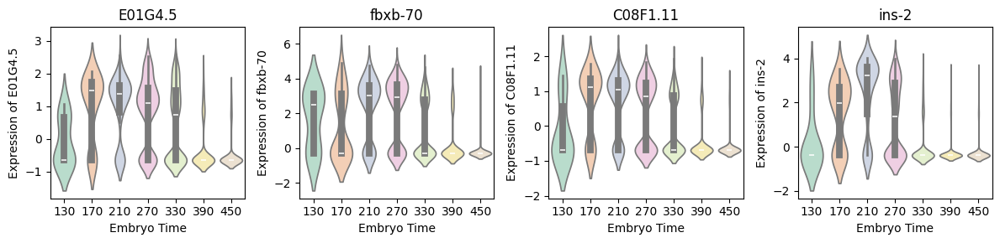

In [384]:
visualize_gene_correlations(band4_data, gene_band4, ['E01G4.5','fbxb-70', 'C08F1.11','ins-2'])

<Figure size 1000x500 with 0 Axes>

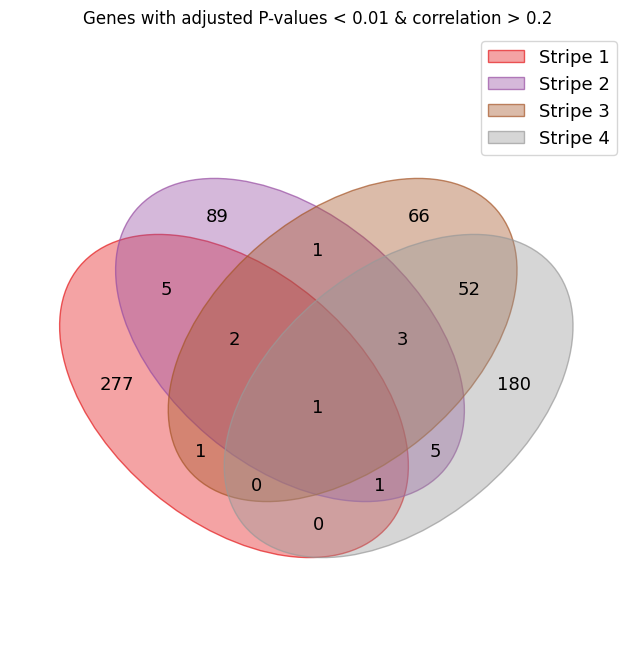

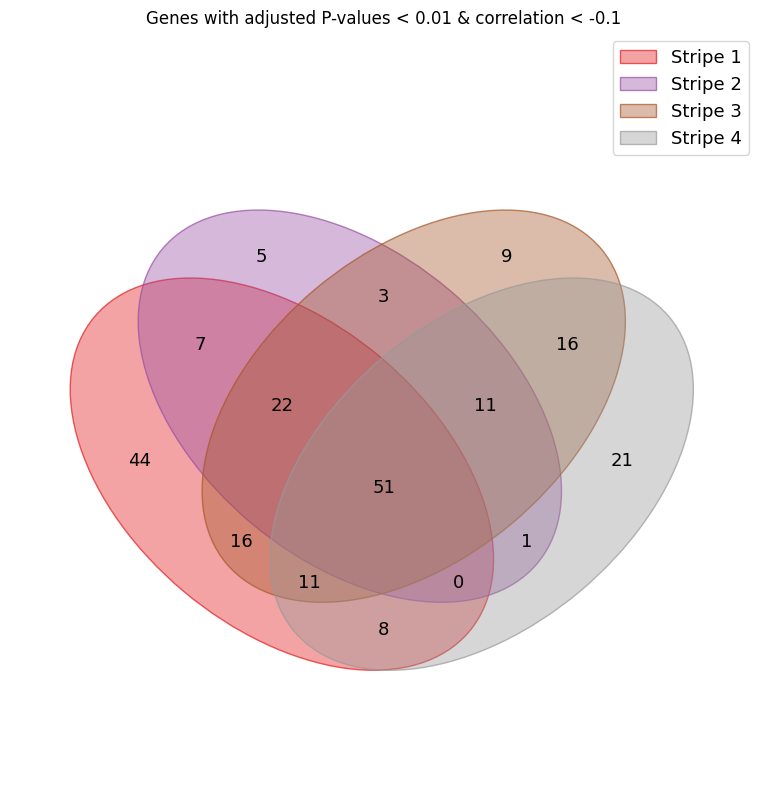

In [423]:
from venn import venn

band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()
band4_genes = band4_results.copy()

# Filter genes with significant adjusted p-values and correlation > 0.1 or < -0.1
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.2) & (band1_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.2) & (band2_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.2) & (band3_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band4_positive = set(band4_genes[(band4_genes['Correlation'] > 0.2) & (band4_genes['Adjusted P-Value'] < 0.01)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.1) & (band1_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.1) & (band2_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.1) & (band3_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band4_negative = set(band4_genes[(band4_genes['Correlation'] < -0.1) & (band4_genes['Adjusted P-Value'] < 0.01)]['Gene'])

# Positive correlations
data_positive = {
    'Stripe 1': band1_positive,
    'Stripe 2': band2_positive,
    'Stripe 3': band3_positive,
    'Stripe 4': band4_positive
}

# Negative correlations
data_negative = {
    'Stripe 1': band1_negative,
    'Stripe 2': band2_negative,
    'Stripe 3': band3_negative,
    'Stripe 4': band4_negative
}

plt.figure(figsize=(10, 5))

venn(data_positive, cmap='Set1')
plt.title('Genes with adjusted P-values < 0.01 & correlation > 0.2')
venn(data_negative, cmap='Set1')
plt.title('Genes with adjusted P-values < 0.01 & correlation < -0.1')

plt.tight_layout()
plt.show()

In [425]:
instersect = band1_negative.intersection(band2_negative.intersection(band3_negative.intersection(band4_negative)))
instersect_list = list(instersect)

with open('instersect_genes.txt', 'w') as f:
    for gene in instersect_list:
        f.write(f"{gene}\n")

In [431]:
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.4) & (band1_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band1_positive_list = list(band1_positive)

with open('band1_positive_genes.txt', 'w') as f:
    for gene in band1_positive_list:
        f.write(f"{gene}\n")

In [432]:
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.3) & (band2_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band2_positive_list = list(band2_positive)

with open('band2_positive_genes.txt', 'w') as f:
    for gene in band2_positive_list:
        f.write(f"{gene}\n")

In [433]:
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.3) & (band3_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band3_positive_list = list(band3_positive)

with open('band3_positive_genes.txt', 'w') as f:
    for gene in band3_positive_list:
        f.write(f"{gene}\n")

In [434]:
band4_positive = set(band4_genes[(band4_genes['Correlation'] > 0.4) & (band4_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band4_positive_list = list(band4_positive)

with open('band4_positive_genes.txt', 'w') as f:
    for gene in band4_positive_list:
        f.write(f"{gene}\n")

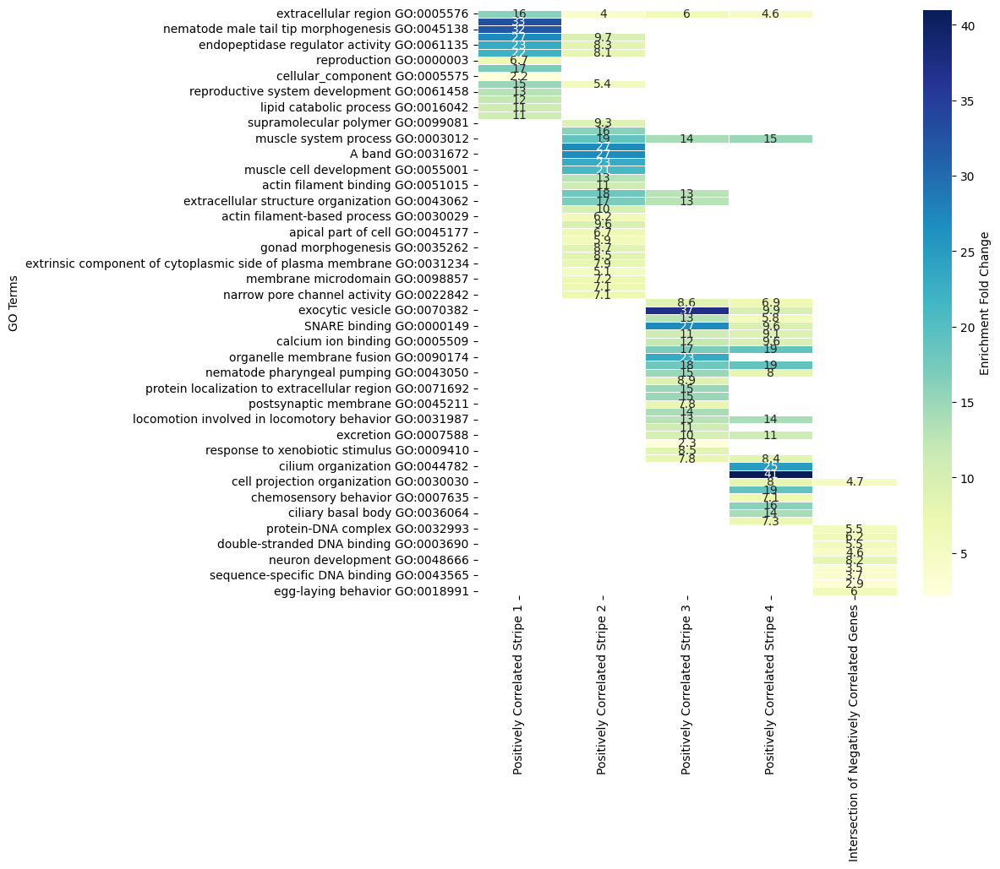

In [435]:
def load_go_data(file_path):
    #
    df = pd.read_csv(file_path, sep="\t")
    return df[['Term', 'Enrichment Fold Change']]

# Load data for each stripe and intersection from WormBase
stripe1_df = load_go_data('celegan_stripe1_pathway.txt')
stripe2_df = load_go_data('celegan_stripe2_pathway.txt')
stripe3_df = load_go_data('celegan_stripe3_pathway.txt')
stripe4_df = load_go_data('celegan_stripe4_pathway.txt')
intersection_df = load_go_data('celegan_intersection_pathways.txt')

stripe1_df.columns = ['GO Term', 'Positively Correlated Stripe 1']
stripe2_df.columns = ['GO Term', 'Positively Correlated Stripe 2']
stripe3_df.columns = ['GO Term', 'Positively Correlated Stripe 3']
stripe4_df.columns = ['GO Term', 'Positively Correlated Stripe 4']
intersection_df.columns = ['GO Term', 'Intersection of Negatively Correlated Genes']

merged_df = pd.merge(stripe1_df, stripe2_df, on='GO Term', how='outer')
merged_df = pd.merge(merged_df, stripe3_df, on='GO Term', how='outer')
merged_df = pd.merge(merged_df, stripe4_df, on='GO Term', how='outer')
merged_df = pd.merge(merged_df, intersection_df, on='GO Term', how='outer')

merged_df.set_index('GO Term', inplace=True)

plt.figure(figsize=(8, 9))
sns.heatmap(merged_df, annot=True, cmap="YlGnBu", cbar_kws={'label': 'Enrichment Fold Change'}, linewidths=0.5)
plt.ylabel('GO Terms')
plt.show()

In [56]:
band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()
band4_genes = band4_results.copy()

band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.45) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.45) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.45) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band4_positive = set(band4_genes[(band4_genes['Correlation'] > 0.45) & (band4_genes['Adjusted P-Value'] < 0.05)]['Gene'])

all_gene = band1_positive.union(band2_positive).union(band3_positive).union(band4_positive)
all_gene

{'C26B9.3',
 'C29F5.1',
 'C33A12.4',
 'C35E7.11',
 'C49F8.3',
 'C52G5.2',
 'E02A10.3',
 'F32D8.7',
 'F41F3.3',
 'F42G8.19',
 'F48D6.4',
 'T05G5.5',
 'T05H10.3',
 'T06G6.3',
 'T10B5.4',
 'Y44A6D.2',
 'abu-13',
 'arl-3',
 'dyf-6',
 'egl-21',
 'far-1',
 'hhat-1',
 'hsp-12.2',
 'let-2',
 'lpr-4',
 'lpr-5',
 'lpr-7',
 'mig-18',
 'mks-2',
 'mlt-9',
 'mup-2',
 'pgal-1',
 'pghm-1',
 'ptb-1',
 'rgs-3',
 'sbt-1',
 'spp-13',
 'tnt-3',
 'ttn-1',
 'unc-15'}

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_5572\3390993459.py:36: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_ramp = plt.cm.get_cmap('Blues')  #use 'Blues' as a base
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


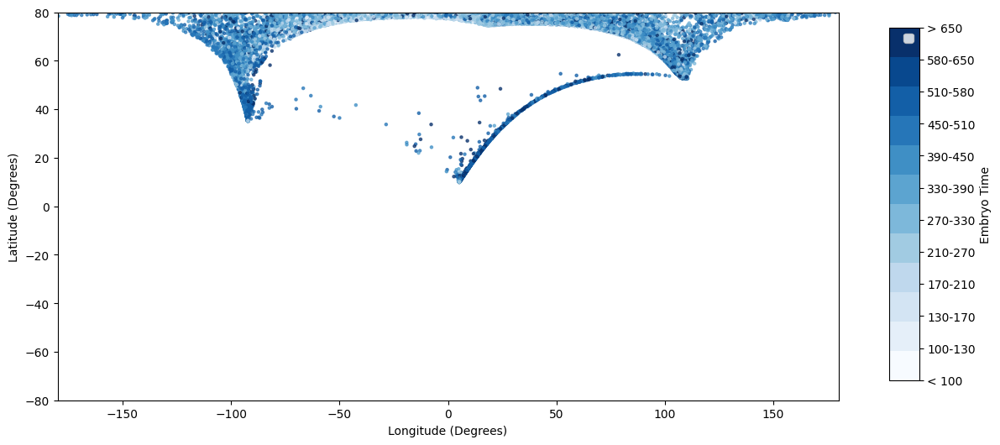

In [76]:
data = pd.read_csv('sim_celegan_pca_exp_2.csv')

data['time'] = data['cluster'].apply(convert_cluster_to_time)
centroid_100_130 = data[data['cluster'] == '100-130'][['PC1', 'PC2', 'PC3']].mean().values

data = pc.align_to_north_pole(data, pcs_columns=['PC1', 'PC2', 'PC3'], cluster_column='cluster', root_node=centroid_100_130)
data = pc.apply_euler_rotation(data, pcs_columns=['PC1', 'PC2', 'PC3'], rotation_angles=[-20,0,0], degrees=True)

longitudes, latitudes = cartesian_to_spherical(data['rotated_PC1'], data['rotated_PC2'], data['rotated_PC3'])
longitudes = np.degrees(longitudes)
latitudes = np.degrees(latitudes)

data['Longitude'] = longitudes
data['Latitude'] = latitudes

categories = ['< 100', "100-130", "130-170", "170-210", "210-270", "270-330", "330-390", 
              "390-450", "450-510", '510-580', '580-650', '> 650' ]
color_ramp = plt.cm.get_cmap('Blues')  
custom_palette = color_ramp(np.linspace(0, 1, len(categories)))
category_codes = data['cluster'].astype('category').cat.codes
custom_cmap = ListedColormap(custom_palette)

fig, ax = plt.subplots(figsize=(12, 6))

cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

ax.scatter(data['Longitude'], data['Latitude'], c=category_codes, cmap=custom_cmap, s=5, alpha=0.7)
ax.set_xlabel('Longitude (Degrees)')
ax.set_ylabel('Latitude (Degrees)')
ax.set_xlim(-180, 180)
ax.set_ylim(-80, 80)

ax.grid(False)
plt.legend()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_5572\3736566217.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjusted to prevent cutting off the color bar


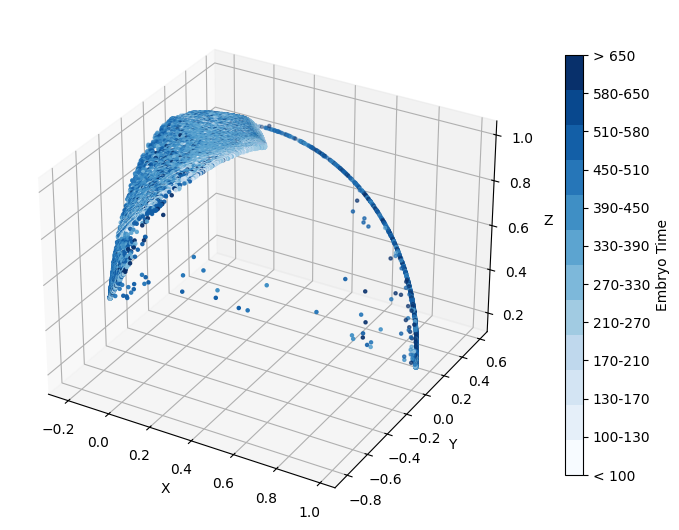

In [77]:
fig = plt.figure(figsize=(6, 6))

plt.subplots_adjust(left=0.1, right=0.85)  
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

ax1 = fig.add_subplot(111, projection='3d')  
scatter1 = ax1.scatter(data['rotated_PC1'], data['rotated_PC2'], data['rotated_PC3'],
                       c=category_codes, cmap=custom_cmap, s=5)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

plt.tight_layout(rect=[0, 0, 0.9, 1]) 
plt.show()

In [439]:
band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()
band4_genes = band4_results.copy()

band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.3) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.3) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band4_positive = set(band4_genes[(band4_genes['Correlation'] > 0.4) & (band4_genes['Adjusted P-Value'] < 0.05)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.3) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.3) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band4_negative = set(band4_genes[(band4_genes['Correlation'] < -0.4) & (band4_genes['Adjusted P-Value'] < 0.05)]['Gene'])

band1_genes = band1_positive.union(band1_negative)
band2_genes = band2_positive.union(band2_negative)
band3_genes = band3_positive.union(band3_negative)
band4_genes = band4_positive.union(band4_negative)

all_band_genes = band1_genes.union(band2_genes).union(band3_genes).union(band4_genes)

all_bands_expression = gene.loc[:, ['Unnamed: 0'] + list(all_band_genes)]
filtered_subset = data[data['Unnamed: 0'].isin(gene['Unnamed: 0'])]
combined_data = pd.merge(filtered_subset, all_bands_expression, on='Unnamed: 0', how='inner')

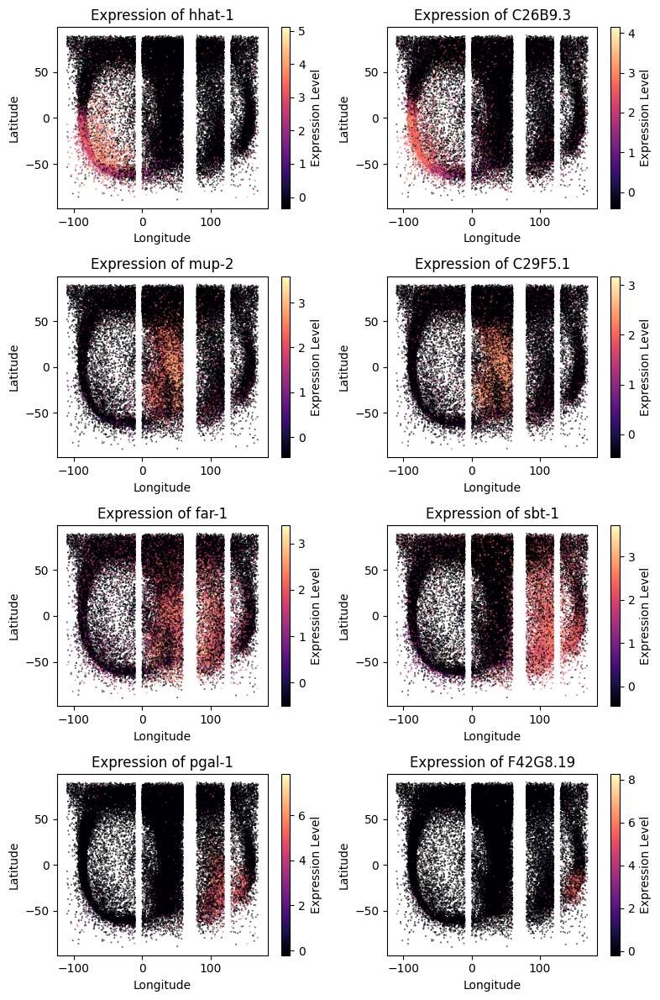

In [476]:
genes = [ 'hhat-1', 'C26B9.3', 'mup-2', 'C29F5.1','far-1', 'sbt-1', 'pgal-1','F42G8.19']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(8, 12))
axes = axes.flatten()  

for i, gene in enumerate(genes):
    sc = axes[i].scatter(combined_data['Longitude'], combined_data['Latitude'],
                         c=combined_data[gene], cmap='magma', s=0.1)
    axes[i].set_title(f'Expression of {gene}')
    axes[i].set_xlabel('Longitude')
    axes[i].set_ylabel('Latitude')
    plt.colorbar(sc, ax=axes[i], label='Expression Level')

plt.tight_layout()
plt.show()

In [5]:
#############################
# Dropping unassigned cells #
#############################
filtered_data = data.dropna(subset=['celltype'])
clusters_to_filter_out = ['< 100', '> 650', '580-650', '510-580']

filtered_data = filtered_data[~filtered_data['cluster'].isin(clusters_to_filter_out)]
centroid_100_130 = filtered_data[filtered_data['cluster'] == '100-130'][['PC1', 'PC2', 'PC3']].mean().values

filtered_data = pc.align_to_north_pole(filtered_data, pcs_columns=['PC1', 'PC2', 'PC3'], cluster_column='cluster', root_node=centroid_100_130)
filtered_data = pc.apply_euler_rotation(filtered_data, pcs_columns=['PC1', 'PC2', 'PC3'], rotation_angles=[-50,0,30], degrees=True)

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\2929822174.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_ramp = plt.cm.get_cmap('Blues')  #use 'Blues' as a base
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


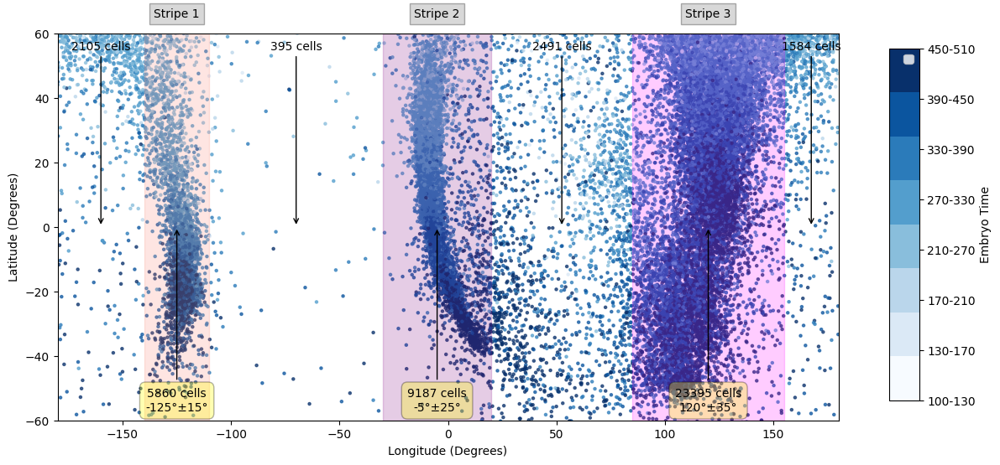

In [8]:
longitudes, latitudes = cartesian_to_spherical(filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'])
longitudes = np.degrees(longitudes)
latitudes = np.degrees(latitudes)

filtered_data['Longitude'] = longitudes
filtered_data['Latitude'] = latitudes

new_longitudes = [-125, -5, 120]
new_bands = [15, 25, 35]
    
categories = ["100-130", "130-170", "170-210", "210-270", "270-330", "330-390", 
              "390-450", "450-510"]
color_ramp = plt.cm.get_cmap('Blues')  
custom_palette = color_ramp(np.linspace(0, 1, len(categories)))
category_codes = filtered_data['cluster'].astype('category').cat.codes
custom_cmap = ListedColormap(custom_palette)

within_counts, between_counts = count_cells_within_bands_wrapped(filtered_data, new_longitudes, new_bands)

fig, ax = plt.subplots(figsize=(12, 6))
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

ax.scatter(filtered_data['Longitude'], filtered_data['Latitude'], c=category_codes, cmap=custom_cmap, s=5, alpha=0.7)
ax.set_xlabel('Longitude (Degrees)')
ax.set_ylabel('Latitude (Degrees)')
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 60)

for i, (lon, band, color) in enumerate(zip(new_longitudes, new_bands, ['salmon', 'purple', 'magenta'])):
    ax.axvspan(lon - band, lon + band, color=color, alpha=0.2)
    ax.text(lon, 65, f'Stripe {i+1}', horizontalalignment='center', color='black', fontsize=10, bbox=dict(facecolor='grey', alpha=0.3))
    ax.annotate(f'{within_counts[i]} cells\n{lon}°±{band}°', xy=(lon, 0), xytext=(lon, -57),
                arrowprops=dict(facecolor='black', arrowstyle='->'),
                ha='center',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', edgecolor='black', alpha=0.3))

for i, count in enumerate(between_counts):
    if i == 0:  
        text_pos = -160  
    elif i == len(between_counts) - 1: 
        text_pos = 167.5  
    else:
        lon_prev = new_longitudes[i - 1] + new_bands[i - 1]
        lon_next = new_longitudes[i] - new_bands[i]
        text_pos = (lon_prev + lon_next) / 2
    ax.annotate(f'{count} cells', xy=(text_pos, 0), xytext=(text_pos, 55),
                arrowprops=dict(facecolor='gray', arrowstyle='->'),
                ha='center')

ax.grid(False)
plt.legend()
plt.show()

In [29]:
def count_cells_in_stripes(df, stripes_info):
    counts = {key: 0 for key in stripes_info}
    for key, info in stripes_info.items():
        lower_bound = info['longitude'] - info['band']
        upper_bound = info['longitude'] + info['band']
        counts[key] = df[(df['Longitude'] >= lower_bound) & (df['Longitude'] <= upper_bound)].shape[0]
    return counts

def plot_stripes_and_annotate(ax, cap_data, stripe_info, counts, total_cells, cap_name):
    for name, info in stripe_info.items():
        longitude_rad = np.radians(info['longitude'])
        band_rad = np.radians(info['band'])
        
        ax.fill_betweenx([0, 90], longitude_rad - band_rad, longitude_rad + band_rad, color='grey', alpha=0.5)
        ax.annotate(f'{name} ({counts[name]} cells)', xy=(longitude_rad, 45), ha='center',
                    va='center', color='darkred', fontsize=10)
    
    cap_r = 90 - np.abs(cap_data['Latitude'])
    cap_theta = np.radians(cap_data['Longitude'])
    ax.scatter(cap_theta, cap_r, c=cap_data['cluster'].astype('category').cat.codes, cmap=custom_cmap, s=5, alpha=0.7)
    ax.set_ylim(0, 90 - 60)  
    ax.set_title(f'{cap_name} Cap - Total Cells: {total_cells}')
    

In [30]:
stripes_info = {
    'Stripe 1': {'longitude': -125, 'band': 15},
    'Stripe 2': {'longitude': -5, 'band': 25},
    'Stripe 3': {'longitude': 120, 'band': 35}
}


northern_cap = filtered_data[filtered_data['Latitude'] > 60]
southern_cap = filtered_data[filtered_data['Latitude'] < -60]

northern_stripe_counts = count_cells_in_stripes(northern_cap, stripes_info)
southern_stripe_counts = count_cells_in_stripes(southern_cap, stripes_info)
northern_stripe_counts

{'Stripe 1': 429, 'Stripe 2': 314, 'Stripe 3': 5017}

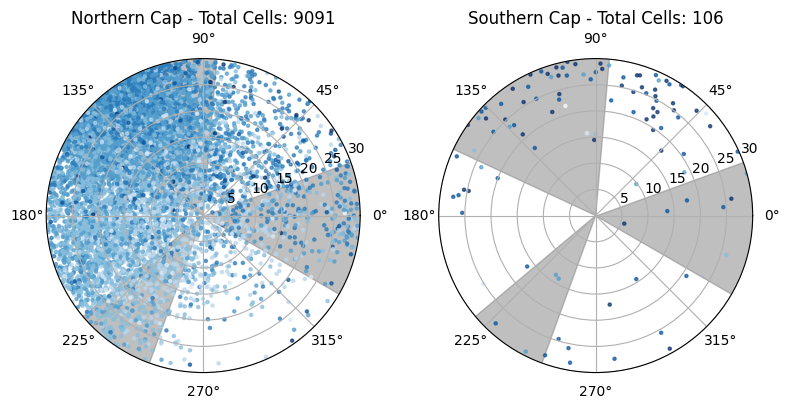

In [32]:
total_northern_cells = northern_cap.shape[0]
total_southern_cells = southern_cap.shape[0]

fig_polar, axs_polar = plt.subplots(1, 2, subplot_kw={'projection': 'polar'}, figsize=(8, 4))

plot_stripes_and_annotate(axs_polar[0], northern_cap, stripes_info, northern_stripe_counts, total_northern_cells, 'Northern')
plot_stripes_and_annotate(axs_polar[1], southern_cap, stripes_info, southern_stripe_counts, total_southern_cells, 'Southern')

plt.tight_layout()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_9496\3314305345.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjusted to prevent cutting off the color bar


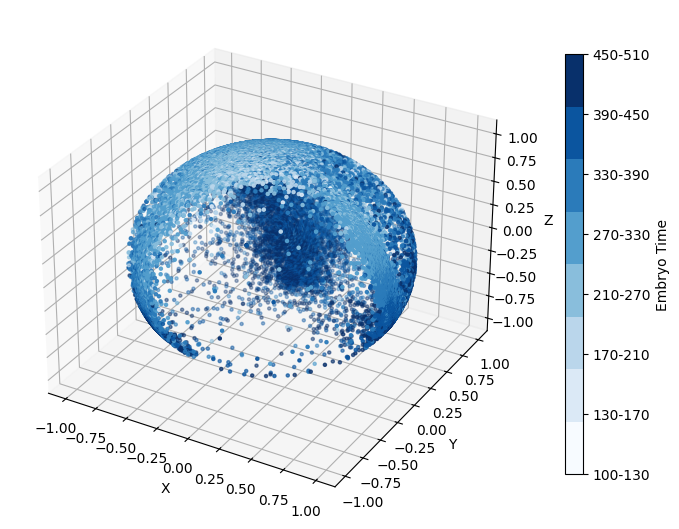

In [44]:
fig = plt.figure(figsize=(6, 6))

plt.subplots_adjust(left=0.1, right=0.85) 
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

ax1 = fig.add_subplot(111, projection='3d')  
scatter1 = ax1.scatter(filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'],
                       c=category_codes, cmap=custom_cmap, s=5)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

plt.tight_layout(rect=[0, 0, 0.9, 1]) 
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1558103159.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  band1_data['cluster_numeric'] = band1_data['cluster'].apply(cluster_to_numeric)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1558103159.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  band2_data['cluster_numeric'] = band2_data['cluster'].apply(cluster_to_numeric)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1558103159.py:12: SettingWithCopyWarning: 
A value is trying to be set 

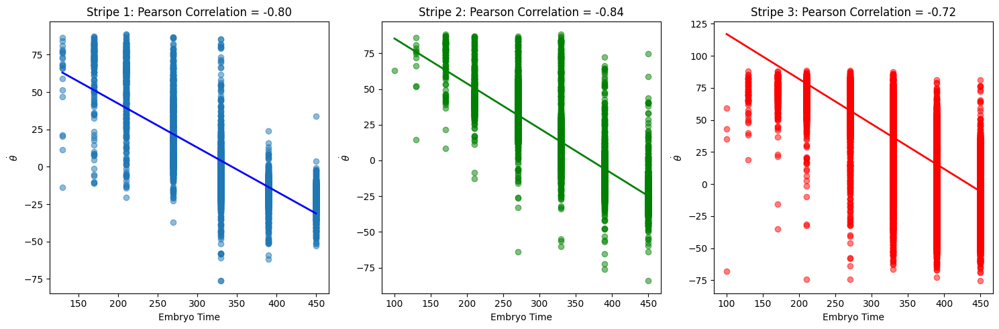

In [11]:
band1_data['cluster_numeric'] = band1_data['cluster'].apply(cluster_to_numeric)
band2_data['cluster_numeric'] = band2_data['cluster'].apply(cluster_to_numeric)
band3_data['cluster_numeric'] = band3_data['cluster'].apply(cluster_to_numeric)

band1_data_sorted = band1_data.sort_values('cluster_numeric')
band2_data_sorted = band2_data.sort_values('cluster_numeric')
band3_data_sorted = band3_data.sort_values('cluster_numeric')

clean_band1_data = band1_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band2_data = band2_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band3_data = band3_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])

model_band1 = LinearRegression().fit(clean_band1_data[['cluster_numeric']], clean_band1_data['Latitude'])
model_band2 = LinearRegression().fit(clean_band2_data[['cluster_numeric']], clean_band2_data['Latitude'])
model_band3 = LinearRegression().fit(clean_band3_data[['cluster_numeric']], clean_band3_data['Latitude'])

theta_pred_band1 = model_band1.predict(clean_band1_data[['cluster_numeric']])
theta_pred_band2 = model_band2.predict(clean_band2_data[['cluster_numeric']])
theta_pred_band3 = model_band3.predict(clean_band3_data[['cluster_numeric']])

corr_band1_clean = clean_band1_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]
corr_band2_clean = clean_band2_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]
corr_band3_clean = clean_band3_data[['Latitude', 'cluster_numeric']].corr().iloc[0, 1]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

axes[0].scatter(clean_band1_data['cluster_numeric'], clean_band1_data['Latitude'], alpha=0.5)
axes[0].plot(clean_band1_data['cluster_numeric'], theta_pred_band1, color='blue', linewidth=2)
axes[0].set_title(f'Stripe 1: Pearson Correlation = {corr_band1_clean:.2f}')
axes[0].set_xlabel('Embryo Time')
axes[0].set_ylabel(r"$\dot{\theta}$")

axes[1].scatter(clean_band2_data['cluster_numeric'], clean_band2_data['Latitude'], alpha=0.5, color='green')
axes[1].plot(clean_band2_data['cluster_numeric'], theta_pred_band2, color='green', linewidth=2)
axes[1].set_title(f'Stripe 2: Pearson Correlation = {corr_band2_clean:.2f}')
axes[1].set_xlabel('Embryo Time')
axes[1].set_ylabel(r"$\dot{\theta}$")

axes[2].scatter(clean_band3_data['cluster_numeric'], clean_band3_data['Latitude'], alpha=0.5, color='red')
axes[2].plot(clean_band3_data['cluster_numeric'], theta_pred_band3, color='red', linewidth=2)
axes[2].set_title(f'Stripe 3: Pearson Correlation = {corr_band3_clean:.2f}')
axes[2].set_xlabel('Embryo Time')
axes[2].set_ylabel(r"$\dot{\theta}$")

plt.tight_layout()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_9496\3058392088.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  band1_data['cluster_numeric'] = band1_data['cluster'].apply(cluster_to_numeric)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_9496\3058392088.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  band2_data['cluster_numeric'] = band2_data['cluster'].apply(cluster_to_numeric)
C:\Users\lyuan13\AppData\Local\Temp\ipykernel_9496\3058392088.py:12: SettingWithCopyWarning: 
A value is trying to be set 

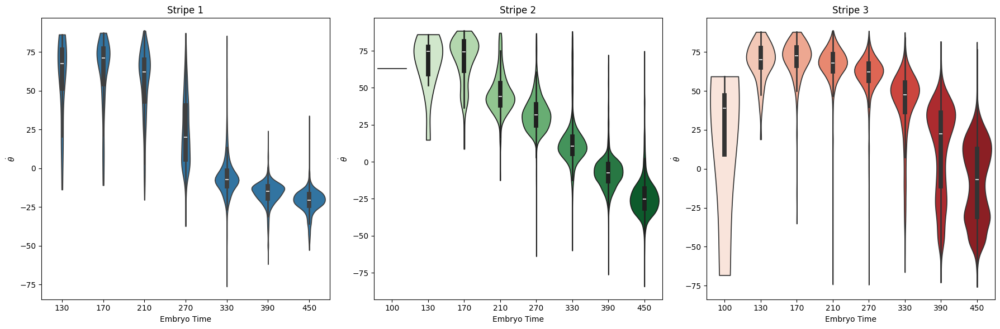

In [62]:
band1_data['cluster_numeric'] = band1_data['cluster'].apply(cluster_to_numeric)
band2_data['cluster_numeric'] = band2_data['cluster'].apply(cluster_to_numeric)
band3_data['cluster_numeric'] = band3_data['cluster'].apply(cluster_to_numeric)

band1_data_sorted = band1_data.sort_values('cluster_numeric')
band2_data_sorted = band2_data.sort_values('cluster_numeric')
band3_data_sorted = band3_data.sort_values('cluster_numeric')

clean_band1_data = band1_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band2_data = band2_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])
clean_band3_data = band3_data_sorted.dropna(subset=['cluster_numeric', 'Latitude'])


fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band1_data, ax=axes[0], cut=0)
axes[0].set_title(f'Stripe 1') 
axes[0].set_xlabel('Embryo Time')
axes[0].set_ylabel(r"$\dot{\theta}$")

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band2_data, ax=axes[1], palette='Greens', cut=0)
axes[1].set_title(f'Stripe 2') 
axes[1].set_xlabel('Embryo Time')
axes[1].set_ylabel(r"$\dot{\theta}$")

sns.violinplot(x='cluster_numeric', y='Latitude', data=clean_band3_data, ax=axes[2], palette='Reds', cut=0)
axes[2].set_title(f'Stripe 3') 
axes[2].set_xlabel('Embryo Time')
axes[2].set_ylabel(r"$\dot{\theta}$")

plt.tight_layout()
plt.show()

In [104]:
gene = pd.read_csv('celegan_2766_gene_38442_cells.csv')

In [13]:
gene_band1 = gene[gene['Unnamed: 0'].isin(filtered_data[filtered_data['band'] == 'Band1']['Unnamed: 0'])]
gene_band2 = gene[gene['Unnamed: 0'].isin(filtered_data[filtered_data['band'] == 'Band2']['Unnamed: 0'])]
gene_band3 = gene[gene['Unnamed: 0'].isin(filtered_data[filtered_data['band'] == 'Band3']['Unnamed: 0'])]

In [19]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import numpy as np

def calculate_spearman_correlation(band_data, gene_data):
    # Merge the datasets on 'Unnamed: 0' to align 'cluster_numeric' with gene expressions
    aligned_data = pd.merge(band_data[['Unnamed: 0', 'cluster_numeric']], gene_data, on='Unnamed: 0')
    
    # Prepare an empty list to store the results
    results = []
    
    # Iterate over each gene in the gene_data DataFrame, skipping 'Unnamed: 0'
    for gene in gene_data.columns[1:]:
        if np.var(aligned_data[gene]) < 1e-8 or np.var(aligned_data['cluster_numeric']) < 1e-8:
            #print(f"Skipping {gene} due to constant data.")
            continue
            
        # Calculate Spearman correlation between cluster_numeric and the gene expression levels
        correlation, p_value = spearmanr(aligned_data['cluster_numeric'], aligned_data[gene])
        
        # Append results
        results.append({
            'Gene': gene,
            'Correlation': correlation,
            'P-value': p_value
        })

    # Convert results to a DataFrame
    results_df = pd.DataFrame(results)
    results_df.dropna(inplace=True)  # Drop any rows with NaN values
    results_df.sort_values(by='Correlation', ascending=False, inplace=True)

    # Adjust p-values for multiple testing
    adjusted_pvals = multipletests(results_df['P-value'], alpha=0.05, method='fdr_bh')[1]
    results_df['Adjusted P-Value'] = adjusted_pvals
    epsilon = 1e-10
    results_df['-log10(Adjusted P-Value)'] = -np.log10(results_df['Adjusted P-Value']+ epsilon) 

    return results_df
#
band1_results = calculate_spearman_correlation(band1_data, gene_band1)
band2_results = calculate_spearman_correlation(band2_data, gene_band2)
band3_results = calculate_spearman_correlation(band3_data, gene_band3)

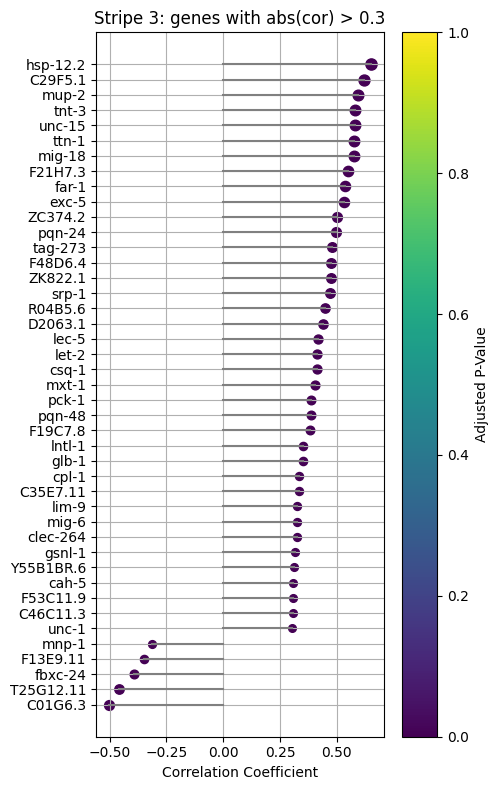

In [59]:
import matplotlib.pyplot as plt
from matplotlib.cm import viridis
from matplotlib.colors import Normalize

#filtered_genes = band1_results[(band1_results['Correlation'] > 0.4) | (band1_results['Correlation'] < -0.4)]
#filtered_genes = band2_results[(band2_results['Correlation'] > 0.45) | (band2_results['Correlation'] < -0.45)]
filtered_genes = band3_results[(band3_results['Correlation'] > 0.3) | (band3_results['Correlation'] < -0.3)]
filtered_genes = filtered_genes.sort_values(by='Correlation', ascending=True)

# Create the figure and axes
fig, ax = plt.subplots(figsize=(5, 8))  # Dynamic height based on number of genes

# Normalize for color mapping based on adjusted p-values
norm = Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])

# Creating lollipops
for index, (i, row) in enumerate(filtered_genes.iterrows()):
    ax.plot([0, row['Correlation']], [index, index], 'gray')  # Line for lollipop
    ax.scatter(row['Correlation'], index, color=sm.to_rgba(row['Adjusted P-Value']), s=np.abs(row['Correlation'])*100)  # Dot for lollipop

# Setting labels with gene names on the y-axis
ax.set_yticks(range(len(filtered_genes)))
ax.set_yticklabels(filtered_genes['Gene'])

# Color bar
cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Adjusted P-Value')
cbar.set_ticks(np.arange(0, 1.1, 0.2))

# Setting x-axis label
ax.set_xlabel('Correlation Coefficient')

# Adding grid and title
ax.grid(True)
ax.set_title('Stripe 3: genes with abs(cor) > 0.3')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()

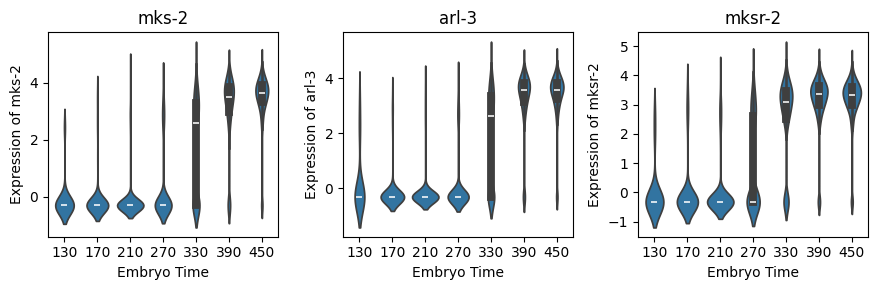

In [66]:
def visualize_gene_correlations(band_data, gene_data, gene_list):
    # Merge the datasets on 'Unnamed: 0'
    aligned_data = pd.merge(band_data[['Unnamed: 0', 'cluster_numeric']], gene_data, on='Unnamed: 0')
    
    # Create a figure to hold the plots
    fig, axs = plt.subplots(1, len(gene_list), figsize=(9, 3))
    
    # Ensure axs is iterable (important for the case of a single gene)
    if len(gene_list) == 1:
        axs = [axs]
    
    # Plotting each specified gene
    for ax, gene in zip(axs, gene_list):
        if gene in aligned_data.columns:
            sns.violinplot(x='cluster_numeric', y=gene, data=aligned_data, ax=ax)
            ax.set_title(f'{gene}')
            ax.set_xlabel('Embryo Time')
            ax.set_ylabel(f'Expression of {gene}')
        else:
            ax.text(0.5, 0.5, f'Gene {gene} not found in data', horizontalalignment='center', verticalalignment='center')
            ax.set_xlabel('Embryo Time')
            ax.set_ylabel(f'Expression of {gene}')
    
    # Adjust layout
    plt.tight_layout()
    plt.show()
visualize_gene_correlations(band1_data, gene_band1, ['mks-2','arl-3','mksr-2'])

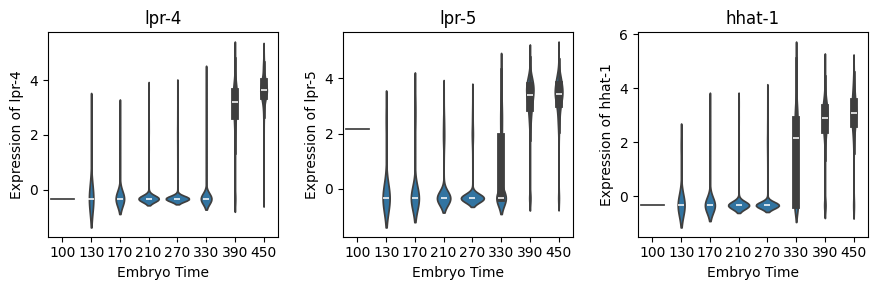

In [67]:
visualize_gene_correlations(band2_data, gene_band2, ['lpr-4','lpr-5','hhat-1'])

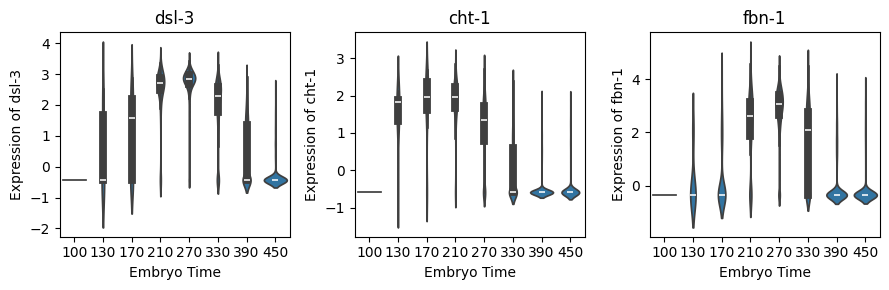

In [69]:
visualize_gene_correlations(band2_data, gene_band2, ['dsl-3','cht-1','fbn-1'])

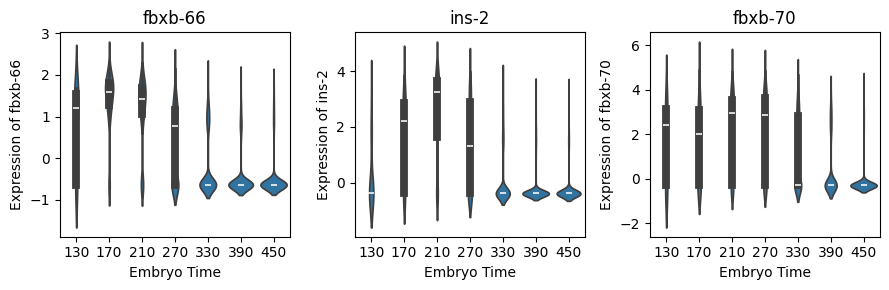

In [70]:
visualize_gene_correlations(band1_data, gene_band1, ['fbxb-66','ins-2','fbxb-70'])

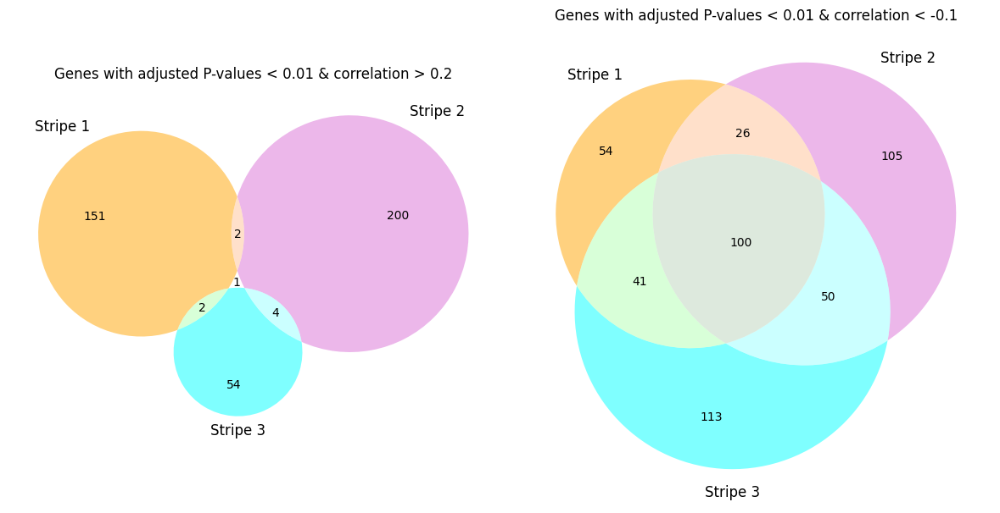

In [80]:
from matplotlib_venn import venn3

band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()

band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.2) & (band1_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.2) & (band2_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.2) & (band3_genes['Adjusted P-Value'] < 0.01)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.1) & (band1_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.1) & (band2_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.1) & (band3_genes['Adjusted P-Value'] < 0.01)]['Gene'])


plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
venn3([band1_positive, band2_positive, band3_positive], 
      ('Stripe 1', 'Stripe 2', 'Stripe 3'), set_colors=("orange", "orchid", "cyan"),alpha=0.5)
plt.title('Genes with adjusted P-values < 0.01 & correlation > 0.2')

plt.subplot(1, 2, 2)
venn3([band1_negative, band2_negative, band3_negative], 
      ('Stripe 1', 'Stripe 2', 'Stripe 3'), set_colors=("orange", "orchid", "cyan"),alpha=0.5)
plt.title('Genes with adjusted P-values < 0.01 & correlation < -0.1')

plt.tight_layout()
plt.show()

In [ ]:
band1_negative.intersection(band2_negative.intersection(band3_negative))

In [98]:
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.1) & (band1_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band1_positive_list = list(band1_positive)

with open('band1_positive_genes.txt', 'w') as f:
    for gene in band1_positive_list:
        f.write(f"{gene}\n")

In [99]:
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.1) & (band2_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band2_positive_list = list(band2_positive)

with open('band2_positive_genes.txt', 'w') as f:
    for gene in band2_positive_list:
        f.write(f"{gene}\n")

In [100]:
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.1) & (band3_genes['Adjusted P-Value'] < 0.01)]['Gene'])
band3_positive_list = list(band3_positive)

with open('band3_positive_genes.txt', 'w') as f:
    for gene in band3_positive_list:
        f.write(f"{gene}\n")

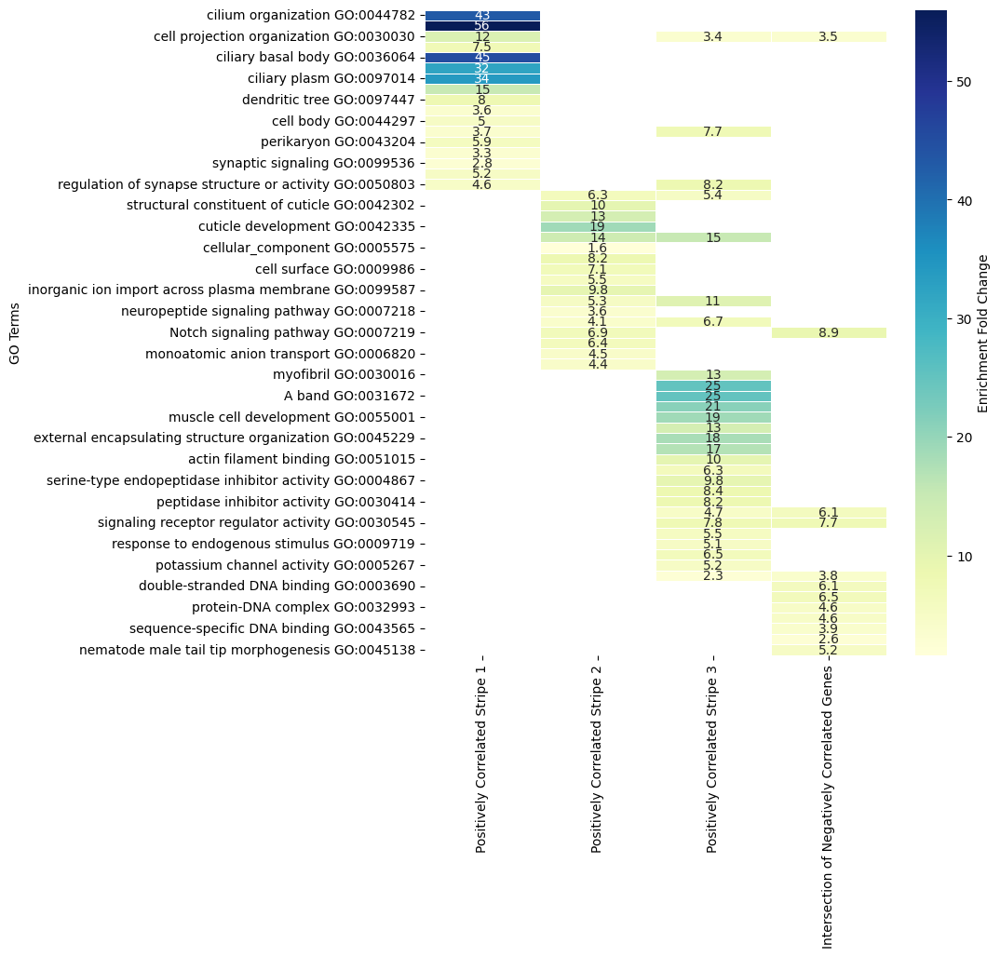

In [102]:
def load_go_data(file_path):
    #
    df = pd.read_csv(file_path, sep="\t")
    return df[['Term', 'Enrichment Fold Change']]

stripe1_df = load_go_data('celegan_stripe1_2.txt')
stripe2_df = load_go_data('celegan_stripe2_2.txt')
stripe3_df = load_go_data('celegan_stripe3_2.txt')
intersection_df = load_go_data('celegan_stripe_intersection.txt')

stripe1_df.columns = ['GO Term', 'Positively Correlated Stripe 1']
stripe2_df.columns = ['GO Term', 'Positively Correlated Stripe 2']
stripe3_df.columns = ['GO Term', 'Positively Correlated Stripe 3']
intersection_df.columns = ['GO Term', 'Intersection of Negatively Correlated Genes']

merged_df = pd.merge(stripe1_df, stripe2_df, on='GO Term', how='outer')
merged_df = pd.merge(merged_df, stripe3_df, on='GO Term', how='outer')
merged_df = pd.merge(merged_df, intersection_df, on='GO Term', how='outer')

merged_df.set_index('GO Term', inplace=True)

plt.figure(figsize=(8, 9))
sns.heatmap(merged_df, annot=True, cmap="YlGnBu", cbar_kws={'label': 'Enrichment Fold Change'}, linewidths=0.5)
plt.ylabel('GO Terms')

plt.show()

In [105]:
band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()

# Filter genes based on specified conditions
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.45) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.3) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.45) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.3) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

# Combine positive and negative gene sets for each band
band1_genes = band1_positive.union(band1_negative)
band2_genes = band2_positive.union(band2_negative)
band3_genes = band3_positive.union(band3_negative)

# Combine all unique genes from all bands
all_band_genes = band1_genes.union(band2_genes).union(band3_genes)

# Subset the gene_expression DataFrame to include only genes from any band
all_bands_expression = gene.loc[:, ['Unnamed: 0'] + list(all_band_genes)]
filtered_subset = filtered_data[filtered_data['Unnamed: 0'].isin(gene['Unnamed: 0'])]
combined_data = pd.merge(filtered_subset, all_bands_expression, on='Unnamed: 0', how='inner')

In [ ]:
# List of genes for which to color the subplots
genes = [ 'mksr-2', 'arl-3', 'lpr-4', 'lpr-5','hsp-12.2', 'mup-2' ]

# Create a 3x2 subplot grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 12))
axes = axes.flatten()  # Flatten the axes array for easy iteration

# Loop through each gene and plot
for i, gene in enumerate(genes):
    sc = axes[i].scatter(combined_data['Longitude'], combined_data['Latitude'],
                         c=combined_data[gene], cmap='magma', s=2)
    axes[i].set_title(f'Expression of {gene}')
    axes[i].set_xlabel('Longitude')
    axes[i].set_ylabel('Latitude')
    plt.colorbar(sc, ax=axes[i], label='Expression Level')

plt.tight_layout()
plt.show()

In [121]:
band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()
# Filter genes based on specified conditions
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.6) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.6) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.5) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.5) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.55) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.5) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

# Combine positive and negative gene sets for each band
band1_genes = band1_positive.union(band1_negative)
band2_genes = band2_positive.union(band2_negative)
band3_genes = band3_positive.union(band3_negative)

# Combine all unique genes from all bands
all_band_genes = band1_genes.union(band2_genes).union(band3_genes)
len(list(all_band_genes))

37

In [122]:
all_band_genes

{'B0365.9',
 'C01G6.3',
 'C26B9.3',
 'C29F5.1',
 'C33A12.4',
 'C52G5.2',
 'F21H7.3',
 'K08B4.2',
 'Y102A11A.5',
 'Y23H5B.8',
 'Y41D4B.26',
 'Y57A10A.23',
 'ZC449.2',
 'arl-3',
 'cht-1',
 'clec-196',
 'cutl-2',
 'dsl-3',
 'exc-5',
 'far-1',
 'fbn-1',
 'hhat-1',
 'hsp-12.2',
 'lbp-3',
 'lpr-1',
 'lpr-4',
 'lpr-5',
 'lpr-6',
 'mig-18',
 'mks-2',
 'mup-2',
 'pmt-2',
 'ptr-4',
 'spp-13',
 'tnt-3',
 'ttn-1',
 'unc-15'}

In [160]:
band1_genes = band1_results.copy()
band2_genes = band2_results.copy()
band3_genes = band3_results.copy()
# Filter genes based on specified conditions
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.45) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.3) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.45) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.3) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

# Combine positive and negative gene sets for each band
band1_genes = band1_positive.union(band1_negative)
band2_genes = band2_positive.union(band2_negative)
band3_genes = band3_positive.union(band3_negative)

# Combine all unique genes from all bands
all_band_genes = band1_genes.union(band2_genes).union(band3_genes)
len(list(all_band_genes))

146

In [161]:
all_band_genes

{'B0365.9',
 'B0393.5',
 'C01G6.3',
 'C06C3.4',
 'C06E7.88',
 'C08F1.11',
 'C09F5.1',
 'C13C12.2',
 'C26B9.3',
 'C29F5.1',
 'C33A12.4',
 'C33G3.4',
 'C34E7.4',
 'C35A5.11',
 'C35E7.11',
 'C43H6.6',
 'C46C11.3',
 'C48E7.1',
 'C52G5.2',
 'C53A5.2',
 'D2063.1',
 'E01G4.5',
 'E02A10.3',
 'F01E11.17',
 'F11E6.9',
 'F13E9.11',
 'F19C7.8',
 'F21H7.3',
 'F26E4.3',
 'F42G8.19',
 'F44E2.4',
 'F46G11.6',
 'F48D6.4',
 'F53C11.9',
 'F55D12.2',
 'F58H1.2',
 'H42K12.3',
 'K07C11.10',
 'K07E3.4',
 'K08B12.1',
 'K08B4.2',
 'M03B6.3',
 'R01H2.8',
 'R04B5.6',
 'R57.2',
 'T02G5.3',
 'T03G11.3',
 'T05G5.5',
 'T05H10.3',
 'T10B5.4',
 'T19B10.2',
 'T25G12.11',
 'W04H10.6',
 'Y102A11A.5',
 'Y102A11A.9',
 'Y23H5B.8',
 'Y41D4B.26',
 'Y54G2A.76',
 'Y55B1BR.6',
 'Y55D5A.1',
 'Y57A10A.23',
 'ZC13.2',
 'ZC374.2',
 'ZC449.2',
 'ZK813.5',
 'ZK822.1',
 'ZK930.6',
 'acn-1',
 'aqp-12',
 'arl-13',
 'arl-3',
 'atf-8',
 'bbs-5',
 'bbs-8',
 'best-14',
 'cah-5',
 'cht-1',
 'clec-196',
 'clec-264',
 'cpl-1',
 'csq-1',
 'cutl-

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\2250881841.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_ramp = plt.cm.get_cmap('Blues')  #use 'Blues' as a base
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


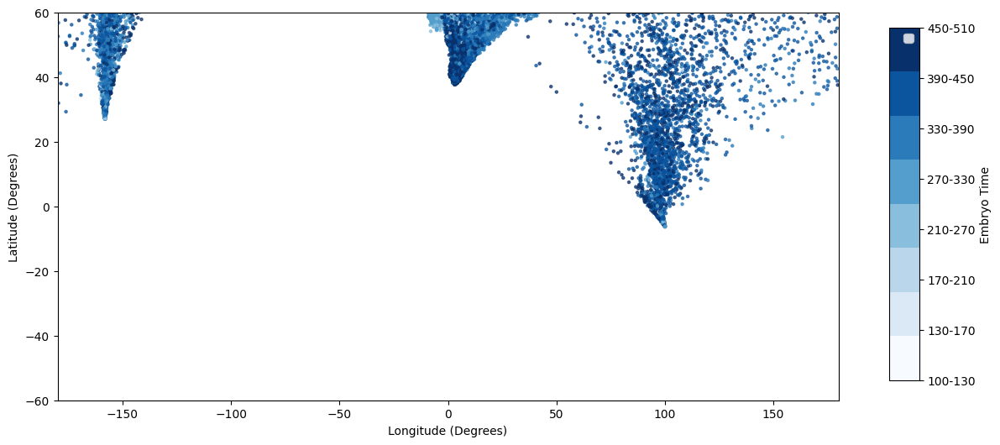

In [158]:
data = pd.read_csv('sim_celegan_pca_exp.csv')
# Apply this function to the 'cluster' column to create a new 'time' column
data['time'] = data['cluster'].apply(convert_cluster_to_time)

filtered_data = data.dropna(subset=['celltype'])
clusters_to_filter_out = ['< 100', '> 650', '580-650', '510-580']
filtered_data = filtered_data[~filtered_data['cluster'].isin(clusters_to_filter_out)]

# Identify the centroid of the 100-130 cluster
centroid_100_130 = filtered_data[filtered_data['cluster'] == '100-130'][['PC1', 'PC2', 'PC3']].mean().values

# Rotate the points so that the centroid of the 100-130 cluster is the north pole
rotated_points = rotate_to_north_pole(filtered_data[['PC1', 'PC2', 'PC3']].values, centroid_100_130)

# Apply Euler Rotation 
#euler_rotation = R.from_euler('xyz', [0,0,0], degrees=True) # 0
#euler_rotation = R.from_euler('xyz', [-90,40,30], degrees=True) # dbl
euler_rotation = R.from_euler('xyz', [-20,0,50], degrees=True) # exp
rotated_points2 = euler_rotation.apply(rotated_points)

filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'] = rotated_points2.T
norms = np.linalg.norm(filtered_data[['rotated_PC1', 'rotated_PC2', 'rotated_PC3']], axis=1)
filtered_data['rotated_PC1'] = filtered_data['rotated_PC1'] / norms
filtered_data['rotated_PC2'] = filtered_data['rotated_PC2'] / norms
filtered_data['rotated_PC3'] = filtered_data['rotated_PC3'] / norms

longitudes, latitudes = cartesian_to_spherical(filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'])
longitudes = np.degrees(longitudes)
latitudes = np.degrees(latitudes)

filtered_data['Longitude'] = longitudes
filtered_data['Latitude'] = latitudes

# Define the categories and the custom color palette
categories = ["100-130", "130-170", "170-210", "210-270", "270-330", "330-390", 
              "390-450", "450-510"]
color_ramp = plt.cm.get_cmap('Blues')  #use 'Blues' as a base
custom_palette = color_ramp(np.linspace(0, 1, len(categories)))
# Convert the categories to a numerical code
category_codes = filtered_data['cluster'].astype('category').cat.codes
# Create a custom colormap based on the palette
custom_cmap = ListedColormap(custom_palette)

fig, ax = plt.subplots(figsize=(12, 6))
# Create the color bar on the leftmost side
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

#plt.scatter(rotated_longitudes_new, rotated_latitudes_new, c=category_codes, cmap=custom_cmap, s=10)
ax.scatter(filtered_data['Longitude'], filtered_data['Latitude'], c=category_codes, cmap=custom_cmap, s=5, alpha=0.7)
ax.set_xlabel('Longitude (Degrees)')
ax.set_ylabel('Latitude (Degrees)')
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 60)

ax.grid(False)
plt.legend()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1613858261.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjusted to prevent cutting off the color bar


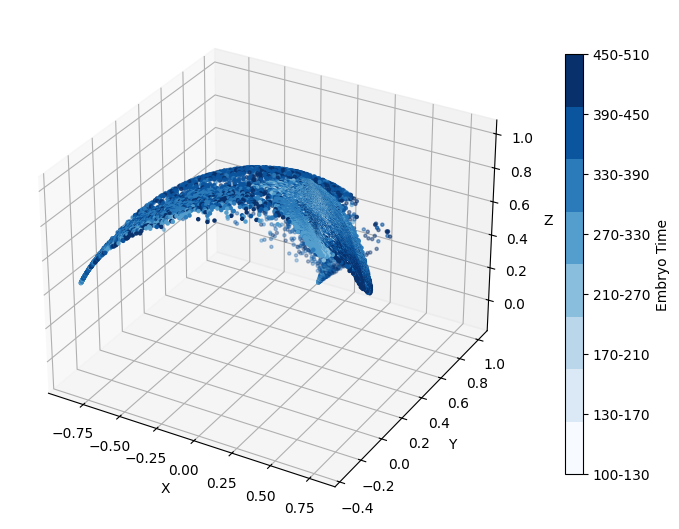

In [159]:
fig = plt.figure(figsize=(6, 6))

# Correct the subplot layout to ensure the color bar does not overlap with the 3D plot
plt.subplots_adjust(left=0.1, right=0.85)  # Adjusted left and right margins

# Create the color bar on the rightmost side 
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])  # Adjusted the position to be on the right side
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

# Create a 3D subplot
ax1 = fig.add_subplot(111, projection='3d')  # 111 means a single plot
scatter1 = ax1.scatter(filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'],
                       c=category_codes, cmap=custom_cmap, s=5)
#ax1.set_title('View 1')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# Adjust tight layout to consider the whole figure dimensions including subplots and colorbar
plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjusted to prevent cutting off the color bar
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\2258848751.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_ramp = plt.cm.get_cmap('Blues')  #use 'Blues' as a base
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


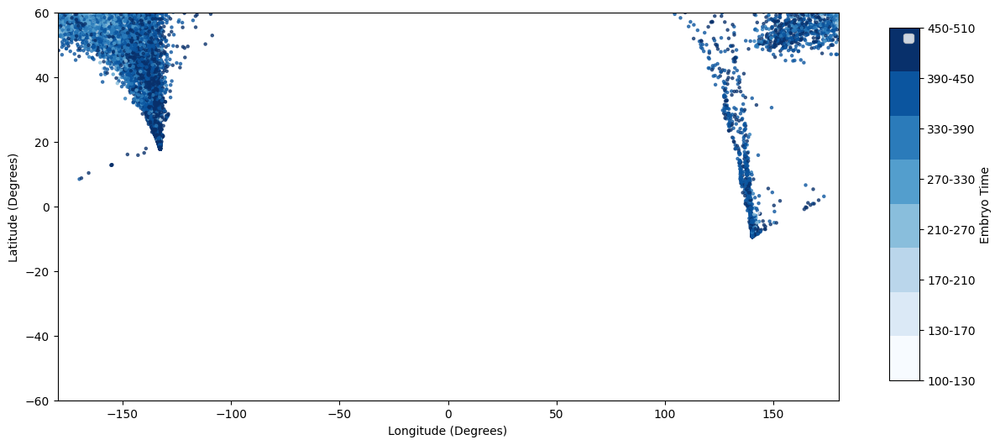

In [177]:
data = pd.read_csv('sim_celegan_pca_exp_146.csv')
# Apply this function to the 'cluster' column to create a new 'time' column
data['time'] = data['cluster'].apply(convert_cluster_to_time)

filtered_data = data.dropna(subset=['celltype'])
clusters_to_filter_out = ['< 100', '> 650', '580-650', '510-580']
filtered_data = filtered_data[~filtered_data['cluster'].isin(clusters_to_filter_out)]

# Identify the centroid of the 100-130 cluster
centroid_100_130 = filtered_data[filtered_data['cluster'] == '100-130'][['PC1', 'PC2', 'PC3']].mean().values

# Rotate the points so that the centroid of the 100-130 cluster is the north pole
rotated_points = rotate_to_north_pole(filtered_data[['PC1', 'PC2', 'PC3']].values, centroid_100_130)

# Apply Euler Rotation 
#euler_rotation = R.from_euler('xyz', [0,0,0], degrees=True) # 0
#euler_rotation = R.from_euler('xyz', [-100,-10,30], degrees=True) # dbl
euler_rotation = R.from_euler('xyz', [-50,0,0], degrees=True) # exp
rotated_points2 = euler_rotation.apply(rotated_points)

filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'] = rotated_points2.T
norms = np.linalg.norm(filtered_data[['rotated_PC1', 'rotated_PC2', 'rotated_PC3']], axis=1)
filtered_data['rotated_PC1'] = filtered_data['rotated_PC1'] / norms
filtered_data['rotated_PC2'] = filtered_data['rotated_PC2'] / norms
filtered_data['rotated_PC3'] = filtered_data['rotated_PC3'] / norms

longitudes, latitudes = cartesian_to_spherical(filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'])
longitudes = np.degrees(longitudes)
latitudes = np.degrees(latitudes)

filtered_data['Longitude'] = longitudes
filtered_data['Latitude'] = latitudes

# Define the categories and the custom color palette
categories = ["100-130", "130-170", "170-210", "210-270", "270-330", "330-390", 
              "390-450", "450-510"]
color_ramp = plt.cm.get_cmap('Blues')  #use 'Blues' as a base
custom_palette = color_ramp(np.linspace(0, 1, len(categories)))
# Convert the categories to a numerical code
category_codes = filtered_data['cluster'].astype('category').cat.codes
# Create a custom colormap based on the palette
custom_cmap = ListedColormap(custom_palette)

fig, ax = plt.subplots(figsize=(12, 6))
# Create the color bar on the leftmost side
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

#plt.scatter(rotated_longitudes_new, rotated_latitudes_new, c=category_codes, cmap=custom_cmap, s=10)
ax.scatter(filtered_data['Longitude'], filtered_data['Latitude'], c=category_codes, cmap=custom_cmap, s=5, alpha=0.7)
ax.set_xlabel('Longitude (Degrees)')
ax.set_ylabel('Latitude (Degrees)')
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 60)

ax.grid(False)
plt.legend()
plt.show()

C:\Users\lyuan13\AppData\Local\Temp\ipykernel_4960\1613858261.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjusted to prevent cutting off the color bar


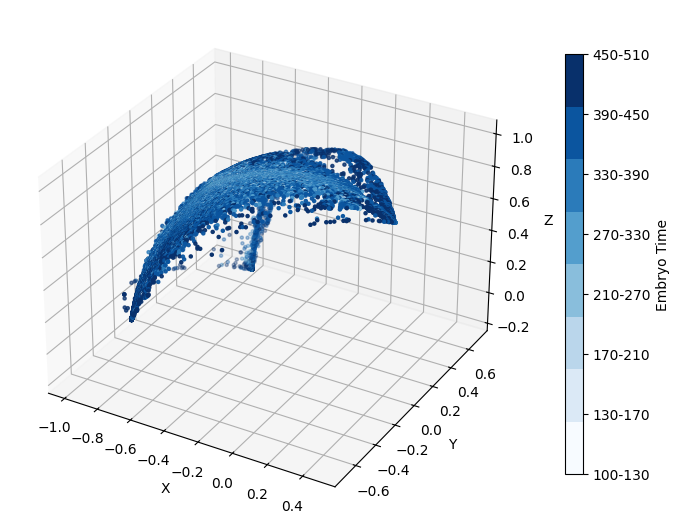

In [178]:
fig = plt.figure(figsize=(6, 6))

# Correct the subplot layout to ensure the color bar does not overlap with the 3D plot
plt.subplots_adjust(left=0.1, right=0.85)  # Adjusted left and right margins

# Create the color bar on the rightmost side 
cbar_ax = fig.add_axes([0.95, 0.15, 0.03, 0.7])  # Adjusted the position to be on the right side
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap), cax=cbar_ax)
cbar.set_ticks(np.linspace(0, 1, len(categories)))
cbar.set_ticklabels(categories)
cbar.set_label('Embryo Time')

# Create a 3D subplot
ax1 = fig.add_subplot(111, projection='3d')  # 111 means a single plot
scatter1 = ax1.scatter(filtered_data['rotated_PC1'], filtered_data['rotated_PC2'], filtered_data['rotated_PC3'],
                       c=category_codes, cmap=custom_cmap, s=5)
#ax1.set_title('View 1')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# Adjust tight layout to consider the whole figure dimensions including subplots and colorbar
plt.tight_layout(rect=[0, 0, 0.9, 1])  # Adjusted to prevent cutting off the color bar
plt.show()

In [ ]:
import statsmodels.api as sm

# Function to calculate correlations and correct p-values for a specific band
def calculate_correlations_for_band(band_category):
    # Filter the data for the given band category
    filtered_band_data = filtered_data[filtered_data['band'] == band_category]
    
    # Extract the corresponding cell IDs
    cell_ids = filtered_band_data['Unnamed: 0'].tolist()
    
    # Find the corresponding rows in the gene dataframe
    gene_filtered = gene[gene['Unnamed: 0'].isin(cell_ids)]
    
    aligned_data = filtered_band_data[filtered_band_data['Unnamed: 0'].isin(gene_filtered['Unnamed: 0'])]
    gene_filtered = gene_filtered.set_index('Unnamed: 0').loc[aligned_data['Unnamed: 0']].reset_index()
    
    # Initialize lists to store results
    gene_names = []
    p_values = []
    correlations = []
    beta = []
    # Calculate correlation for each gene with the theta column
    for gene_name in gene_filtered.columns[1:]:  # Skipping the 'Unnamed: 0' column
        gene_expression = gene_filtered[gene_name]
        theta_values = filtered_band_data.loc[filtered_band_data['Unnamed: 0'].isin(cell_ids), 'Latitude']
        
        # Calculate Pearson correlation
        correlation, p_value = spearmanr(gene_expression[gene_expression != 0], theta_values[gene_expression != 0])
        #X = sm.add_constant(theta_values)  # Adds a constant term to the predictor
        #y = gene_expression
        #X = X.reset_index(drop=True)
        #y = y.reset_index(drop=True)
        model = sm.OLS(y, X).fit()
        
        # Store the results
        gene_names.append(gene_name)
        beta.append(model.params['Latitude'])
        correlations.append(model.rsquared)
        p_values.append(model.pvalues['Latitude'])
    
    # Correct for multiple testing using Benjamini-Hochberg method
    #rejected, corrected_p_values = smm.multipletests(p_values, method='fdr_bh')[:2]
    
    # Create a results DataFrame
    results_df = pd.DataFrame({
        'Gene': gene_names,
        'R_squared': correlations,
        'P-Value': p_values,
        'Beta': beta
    })
    
    return results_df

# Calculate correlations for each band category
band1_results = calculate_correlations_for_band('Band1')
band2_results = calculate_correlations_for_band('Band2')
band3_results = calculate_correlations_for_band('Band3')

In [107]:
band1_results

,Gene,R_squared,P-Value,Beta
0,cutl-24,0.015014,4.804148e-21,-0.005584
1,pnc-1,0.044293,1.161687e-59,-0.010353
2,R02D3.1,0.001037,1.371256e-02,0.000568
3,T21D12.12,0.000284,1.971425e-01,-0.000137
4,T21D12.7,0.000601,6.062125e-02,-0.000343
...,...,...,...,...
2761,R03C1.1,0.001358,4.789956e-03,-0.000803
2762,Y53F4B.20,0.001862,9.536432e-04,-0.002481
2763,Y53F4B.27,0.002030,5.599103e-04,-0.000764
2764,gst-28,0.001288,5.999638e-03,-0.000475


In [109]:
bandband1_results = band1_results.dropna().sort_values(by='Beta', ascending=False)
bandband2_results = band2_results.dropna().sort_values(by='Beta', ascending=False)
bandband3_results = band3_results.dropna().sort_values(by='Beta', ascending=False)

In [113]:
bandband3_results.head()

,Gene,R_squared,P-Value,Beta
2330,fbxc-24,0.192125,0.0,0.017937
1317,T25G12.11,0.160956,0.0,0.013914
2593,C01G6.3,0.189711,0.0,0.012354
2721,E01G4.5,0.157822,0.0,0.011921
2350,C08F1.11,0.128544,0.0,0.011675


In [114]:
from statsmodels.stats.multitest import multipletests
epsilon = 1e-308

for data in [bandband1_results, bandband2_results, bandband3_results]:
    data['Adjusted P-Value'] = multipletests(data['P-Value'], alpha=0.01, method='fdr_bh')[1]
    data['-log10(Adjusted P-Value)'] = -np.log10(data['Adjusted P-Value'])

C:\Users\lyuan13\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arraylike.py:396: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\lyuan13\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arraylike.py:396: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\lyuan13\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arraylike.py:396: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [23]:
band1_results.to_csv('band1_genes.csv')

In [ ]:
from adjustText import adjust_text

data = band1_results.copy()
# Redefine the thresholds
# Define thresholds for significance
threshold_positive = 0.4
threshold_negative = -0.3

# Categorize the genes
data['color'] = 'grey'  # Default color for non-significant genes
data.loc[(data['Correlation'] > 0) & (data['Adjusted P-Value'] < 0.05), 'color'] = 'khaki'
data.loc[(data['Correlation'] < 0) & (data['Adjusted P-Value'] < 0.05), 'color'] = 'darkkhaki'

# Prepare the plot
plt.figure(figsize=(7, 4))
plt.scatter(data['Correlation'], data['-log10(Adjusted P-Value)'], color=data['color'], alpha=0.7)

# Add vertical dashed lines at the correlation thresholds
plt.axvline(x=threshold_positive, color='black', linestyle='--', linewidth=1)
plt.axvline(x=threshold_negative, color='black', linestyle='--', linewidth=1)

# Annotate the top 10 genes with positive and negative correlations
top_positive_genes = data[(data['Correlation'] > 0.4) & (data['Adjusted P-Value'] < 0.05)] #.nlargest(10, 'Correlation')
top_negative_genes = data[(data['Correlation'] < -0.3) & (data['Adjusted P-Value'] < 0.05)] #.nsmallest(10, 'Correlation')

texts = []
for i, row in top_positive_genes.iterrows():
    texts.append(plt.text(row['Correlation'], row['-log10(Adjusted P-Value)'], row['Gene'], fontsize=10, color='black'))

for i, row in top_negative_genes.iterrows():
    texts.append(plt.text(row['Correlation'], row['-log10(Adjusted P-Value)'], row['Gene'], fontsize=10, color='black'))

# Adjust text to prevent overlap
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

# Formatting according to Nature guidelines
plt.axhline(0, color='grey', lw=1)
plt.xlabel('Correlation', fontsize=10)
plt.ylabel('-log10(Adjusted P-Value)', fontsize=10)
plt.title('Stripe 3', fontsize=12)
plt.ylim(0,100)
plt.grid(False)

#
plt.tight_layout()
plt.show()

In [18]:
filtered_data.head()

,Unnamed: 0.1,Unnamed: 0,PC1,PC2,PC3,cluster,celltype,time,theta,phi,longitude,latitude,band
0,0,AAACCTGAGACAATAC-300.1.1,-0.143895,-0.953310,0.265506,330-390,Body_wall_muscle,360.0,1.302067,-1.720607,-158.843378,90.0,Band1
1,3,AAACCTGAGTTGAGTA-300.1.1,-0.073152,-0.959201,-0.273098,270-330,Body_wall_muscle,300.0,1.847408,-1.646912,-99.389554,90.0,Outside
2,4,AAACCTGCAAGACGTG-300.1.1,-0.860884,0.150128,-0.486149,330-390,Ciliated_amphid_neuron,360.0,2.078474,2.968940,-159.014597,-90.0,Band1
3,5,AAACCTGCAAGGTTCT-300.1.1,-0.231894,-0.865491,-0.444016,270-330,Pharyngeal_neuron,300.0,2.030872,-1.832581,-112.409283,90.0,Outside
4,6,AAACCTGCACGTTGGC-300.1.1,0.621639,0.079307,-0.779278,330-390,Hypodermis,360.0,2.464310,0.126891,-41.822793,-90.0,Band2


In [31]:
band1_genes = bandband1_results.copy()
band2_genes = bandband2_results.copy()
band3_genes = bandband3_results.copy()

# Filter genes based on specified conditions
band1_positive = set(band1_genes[(band1_genes['Correlation'] > 0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_positive = set(band2_genes[(band2_genes['Correlation'] > 0.4) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_positive = set(band3_genes[(band3_genes['Correlation'] > 0.2) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

band1_negative = set(band1_genes[(band1_genes['Correlation'] < -0.4) & (band1_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band2_negative = set(band2_genes[(band2_genes['Correlation'] < -0.4) & (band2_genes['Adjusted P-Value'] < 0.05)]['Gene'])
band3_negative = set(band3_genes[(band3_genes['Correlation'] < -0.2) & (band3_genes['Adjusted P-Value'] < 0.05)]['Gene'])

# Combine positive and negative gene sets for each band
band1_genes = band1_positive.union(band1_negative)
band2_genes = band2_positive.union(band2_negative)
band3_genes = band3_positive.union(band3_negative)

# Combine all unique genes from all bands
all_band_genes = band1_genes.union(band2_genes).union(band3_genes)

# Subset the gene_expression DataFrame to include only genes from any band
all_bands_expression = gene.loc[:, ['Unnamed: 0'] + list(all_band_genes)]
combined_data = pd.merge(filtered_subset, all_bands_expression, on='Unnamed: 0', how='inner')

(11056, 99)

In [ ]:
band1_positive

In [34]:
combined_data.to_csv('11056_band_cells_with_98_genes.csv')

In [ ]:
band1_negative.intersection(band2_negative)

In [55]:
# List of target gene names
gene_names = ['nid-1', 'spp-15', 'clec-196', 'gst-20', 'nphp-1', 'ugt-50']
subset_df = gene[gene_names]

In [59]:
bands = filtered_data[filtered_data['band'].isin(['Band1', 'Band2', 'Band3'])]
bands

,Unnamed: 0,PC1,PC2,PC3,cluster,celltype,time,theta,phi,longitude,latitude,band
0,AAACCTGAGACAATAC-300.1.1,-0.143895,-0.953310,0.265506,330-390,Body_wall_muscle,360.0,1.302067,-1.720607,-158.843378,90.0,Band1
4,AAACCTGCAAGACGTG-300.1.1,-0.860884,0.150128,-0.486149,330-390,Ciliated_amphid_neuron,360.0,2.078474,2.968940,-159.014597,-90.0,Band1
6,AAACCTGCACGTTGGC-300.1.1,0.621639,0.079307,-0.779278,330-390,Hypodermis,360.0,2.464310,0.126891,-41.822793,-90.0,Band2
22,AAACGGGCAGTCGTGC-300.1.1,0.437975,-0.457416,-0.773918,210-270,Seam_cell,240.0,2.455801,-0.807106,-57.929136,90.0,Band2
27,AAAGATGAGAGTCGGT-300.1.1,0.205824,-0.059982,0.976749,330-390,Intestine,360.0,0.216063,-0.283570,74.411618,90.0,Band3
...,...,...,...,...,...,...,...,...,...,...,...,...
85954,GGCTCGATCTATCGCC-b01,0.148752,-0.565776,0.811031,330-390,Rectal_gland,360.0,0.624885,-1.313699,72.800664,90.0,Band3
85963,TATCTCAAGGGTCTCC-b01,0.089605,-0.344400,0.934537,390-450,Rectal_gland,420.0,0.363840,-1.316262,82.254622,90.0,Band3
85981,AGCCTAAAGTACCGGA-b02,0.223390,-0.111350,0.968348,390-450,Rectal_gland,420.0,0.252271,-0.462411,72.680006,90.0,Band3
86013,GTAGGCCTCTACTATC-b02,0.476267,-0.712331,-0.515513,270-330,Rectal_cell,300.0,2.112403,-0.981454,-50.482772,90.0,Band2


In [56]:
subset_df

,nid-1,spp-15,clec-196,gst-20,nphp-1,ugt-50
0,2.572499,2.492271,-0.516790,-0.479539,-0.314573,-0.785535
1,-0.476112,-0.566809,-0.516790,-0.479539,3.912730,0.672478
2,-0.476112,-0.566809,2.080997,2.360554,-0.314573,0.363079
3,-0.476112,-0.566809,1.431794,1.275039,-0.314573,-0.785535
4,-0.476112,-0.566809,1.043366,1.035628,-0.314573,0.513427
...,...,...,...,...,...,...
11051,-0.476112,-0.566809,1.678269,-0.479539,-0.314573,-0.785535
11052,-0.476112,-0.566809,-0.516790,-0.479539,-0.314573,-0.785535
11053,-0.476112,-0.566809,-0.516790,-0.479539,-0.314573,-0.785535
11054,-0.476112,-0.566809,-0.516790,-0.479539,-0.314573,1.727091


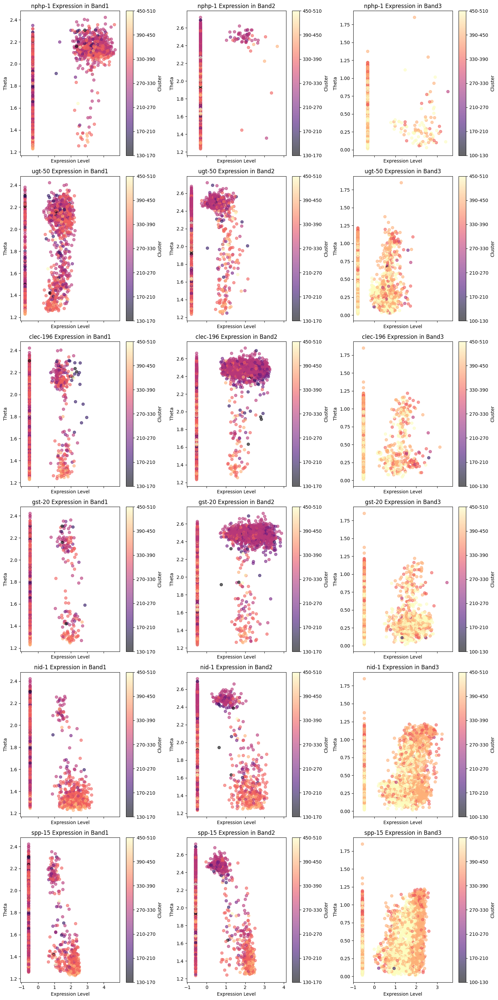

In [72]:
clean_data = combined_data.copy()

# Filtering out clusters '<100' and '>650'
clean_data = clean_data[~clean_data['cluster'].isin(['< 100', '> 650'])]

band1_data = clean_data[clean_data['band'] == 'Band1']
band2_data = clean_data[clean_data['band'] == 'Band2']
band3_data = clean_data[clean_data['band'] == 'Band3']

# List of genes to analyze
genes = ['nphp-1', 'ugt-50', 'clec-196', 'gst-20', 'nid-1', 'spp-15']

# Setting up the plot
fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(15, 5 * len(genes)), sharex='col')

# Define colormap
cmap = plt.get_cmap('magma')
cluster_names = combined_data['cluster'].astype('category').cat.categories

# Plotting
for i, gene in enumerate(genes):
    if gene in combined_data.columns:
        for j, band_data in enumerate([band1_data, band2_data, band3_data]):
            cluster_names = band_data['cluster'].astype('category').cat.categories
            sc = axes[i, j].scatter(band_data[gene], band_data['theta'], c=band_data['cluster'].astype('category').cat.codes, cmap=cmap, alpha=0.6)
            axes[i, j].set_title(f'{gene} Expression in Band{j+1}')
            axes[i, j].set_xlabel('Expression Level')
            axes[i, j].set_ylabel('Theta')
            #fig.colorbar(sc, ax=axes[i, j], label='Cluster')
            
            # Create a color bar with actual cluster names
            cbar = fig.colorbar(sc, ax=axes[i, j], ticks=np.arange(len(cluster_names)))
            cbar.set_label('Cluster')
            cbar.set_ticklabels(cluster_names)
    else:
        for j in range(3):
            axes[i, j].text(0.5, 0.5, f'{gene} not found', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)

plt.tight_layout()
plt.show()

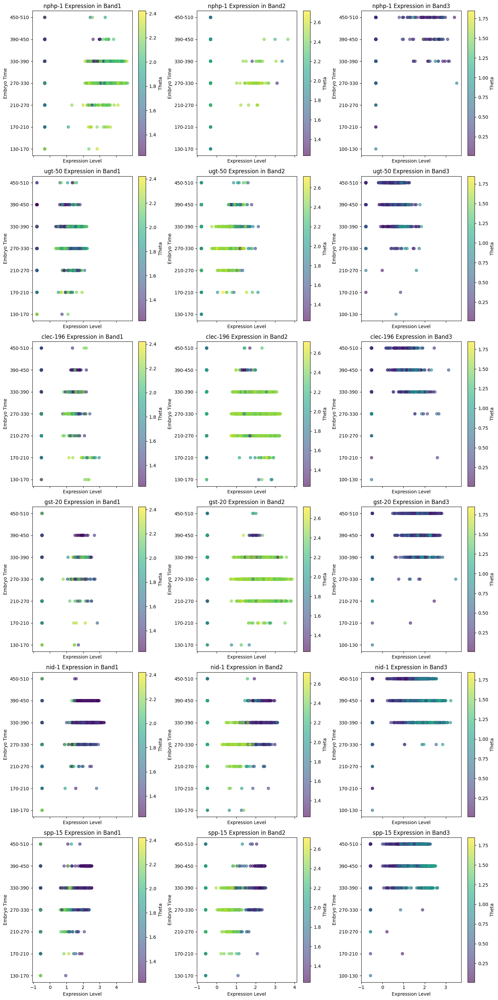

In [74]:
# Adjusting plots to annotate y-axis labels with actual cluster categories
fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(15, 30), sharex='col')
cmap = plt.get_cmap('viridis')

for i, gene in enumerate(genes):
    if gene in combined_data.columns:
        for j, band_data in enumerate([band1_data, band2_data, band3_data]):
            # Convert cluster names to category codes for plotting
            cluster_codes = band_data['cluster'].astype('category').cat.codes
            cluster_categories = band_data['cluster'].astype('category').cat.categories
            sc = axes[i, j].scatter(band_data[gene], cluster_codes, c=band_data['theta'], cmap=cmap, alpha=0.6)
            axes[i, j].set_title(f'{gene} Expression in Band{j+1}')
            axes[i, j].set_xlabel('Expression Level')
            axes[i, j].set_ylabel('Embryo Time')

            # Annotate y-axis with actual cluster names
            axes[i, j].set_yticks(range(len(cluster_categories)))
            axes[i, j].set_yticklabels(cluster_categories)

            # Color bar for theta
            cbar = fig.colorbar(sc, ax=axes[i, j])
            cbar.set_label('Theta')
    else:
        for j in range(3):
            axes[i, j].text(0.5, 0.5, f'{gene} not found', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)

plt.tight_layout()
plt.show()


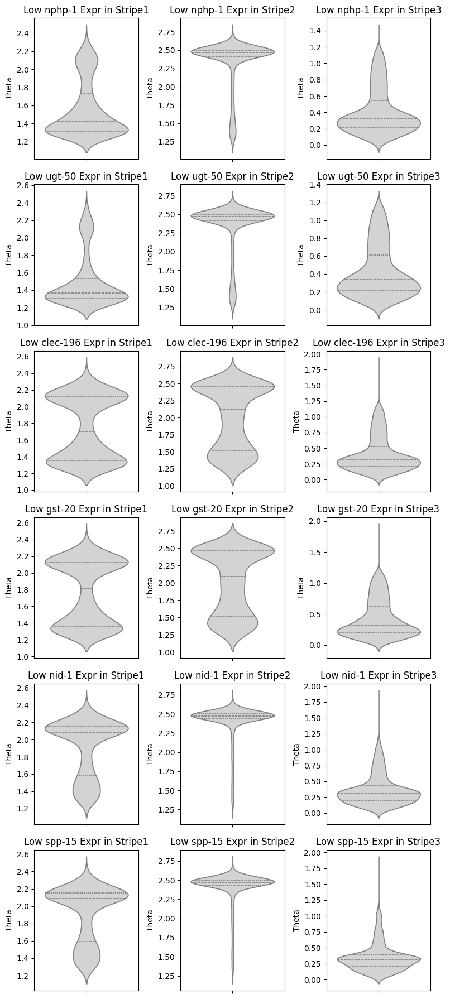

In [70]:
band1_data = combined_data[combined_data['band'] == 'Band1']
band2_data = combined_data[combined_data['band'] == 'Band2']
band3_data = combined_data[combined_data['band'] == 'Band3']

# List of genes to analyze
genes = ['nphp-1', 'ugt-50', 'clec-196', 'gst-20', 'nid-1', 'spp-15']

fig, axes = plt.subplots(nrows=len(genes), ncols=3, figsize=(8, 3 * len(genes)))

for i, gene in enumerate(genes):
    if gene in combined_data.columns:
        for j, band_data in enumerate([band1_data, band2_data, band3_data]):
            # Filter data for gene expression < 0
            negative_expression_data = band_data[band_data[gene] < -0.1]

            # Violin plot for negative expressions
            sns.violinplot(y=negative_expression_data['theta'], ax=axes[i, j], inner='quartile', color='lightgrey')
            axes[i, j].set_title(f'Low {gene} Expr in Stripe{j+1}')
            axes[i, j].set_ylabel('Theta')
    else:
        for j in range(3):
            axes[i, j].text(0.5, 0.5, f'{gene} not found', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)

plt.tight_layout()
plt.show()

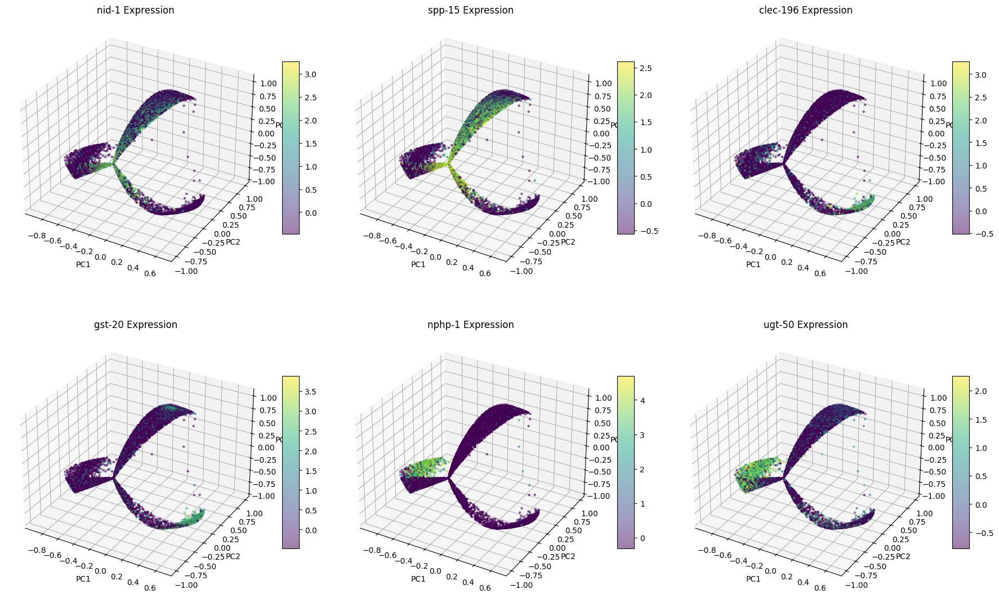

In [63]:
# Create a figure with 6 subplots (2 rows by 3 columns)
fig = plt.figure(figsize=(18, 12))

for i, gene in enumerate(gene_names):
    ax = fig.add_subplot(2, 3, i + 1, projection='3d')
    sc = ax.scatter(bands['PC1'], bands['PC2'], bands['PC3'], c=subset_df[gene], cmap='viridis', s=5, alpha=0.5)
    ax.set_title(f'{gene} Expression')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    fig.colorbar(sc, ax=ax, shrink=0.5, aspect=10)

# Adjust layout
plt.tight_layout()
plt.show()

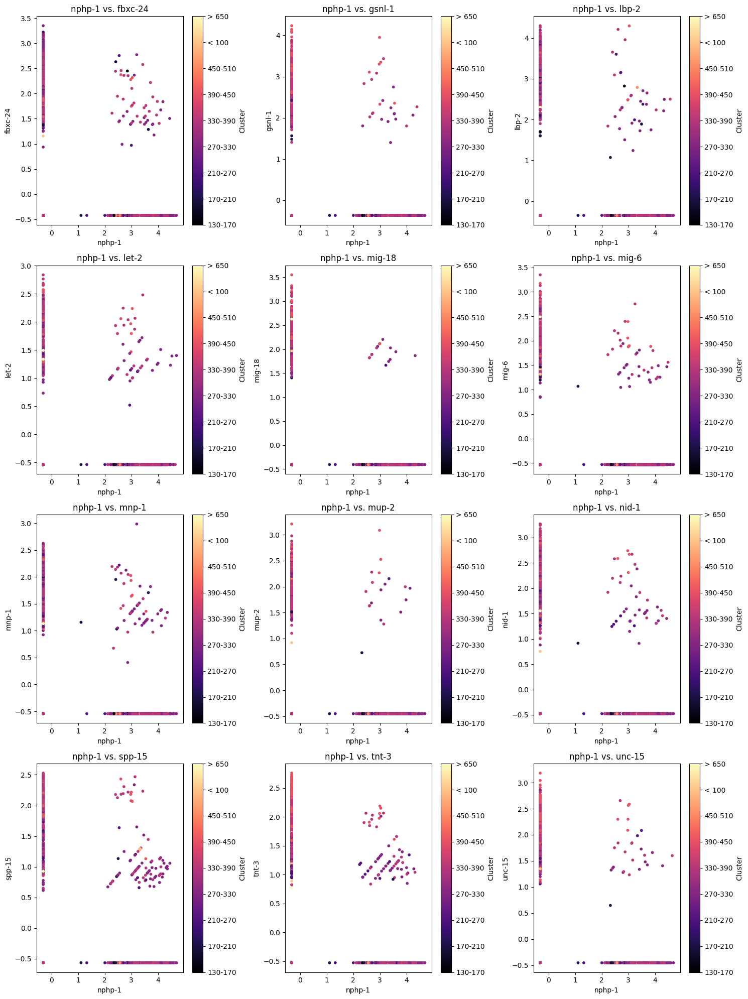

In [46]:
compare_genes_nphp1 = [
    'fbxc-24', 'gsnl-1', 'lbp-2', 'let-2', 'mig-18', 'mig-6',
    'mnp-1', 'mup-2', 'nid-1', 'spp-15', 'tnt-3', 'unc-15'
]

band1_data = combined_data[combined_data['band'] == 'Band1']

# Set up the subplot grid
num_plots_nphp1 = len(compare_genes_nphp1)
cols_nphp1 = 3
rows_nphp1 = (num_plots_nphp1 + cols_nphp1 - 1) // cols_nphp1  # Calculate needed rows

# Create a color map and norm to handle the coloring and labeling of clusters
cluster_names = band1_data['cluster'].astype('category').cat.categories
cmap = plt.cm.magma  # 
norm = plt.Normalize(vmin=0, vmax=len(cluster_names)-1)

fig, axes = plt.subplots(nrows=rows_nphp1, ncols=cols_nphp1, figsize=(15, 5 * rows_nphp1))
axes = axes.flatten()

# Plot 'nphp-1' against each gene in the list
for i, gene_y in enumerate(compare_genes_nphp1):
    if 'nphp-1' in band1_data.columns and gene_y in band1_data.columns:
        sc = axes[i].scatter(band1_data['nphp-1'], band1_data[gene_y],
                             c=band1_data['cluster'].astype('category').cat.codes, cmap=cmap, norm=norm, s=10)
        axes[i].set_title(f'nphp-1 vs. {gene_y}')
        axes[i].set_xlabel('nphp-1')
        axes[i].set_ylabel(gene_y)

        # Create a color bar with actual cluster names
        cbar = fig.colorbar(sc, ax=axes[i], ticks=np.arange(len(cluster_names)))
        cbar.set_label('Cluster')
        cbar.set_ticklabels(cluster_names)
    else:
        axes[i].set_visible(False)  # Hide unused axes

plt.tight_layout()
plt.show()

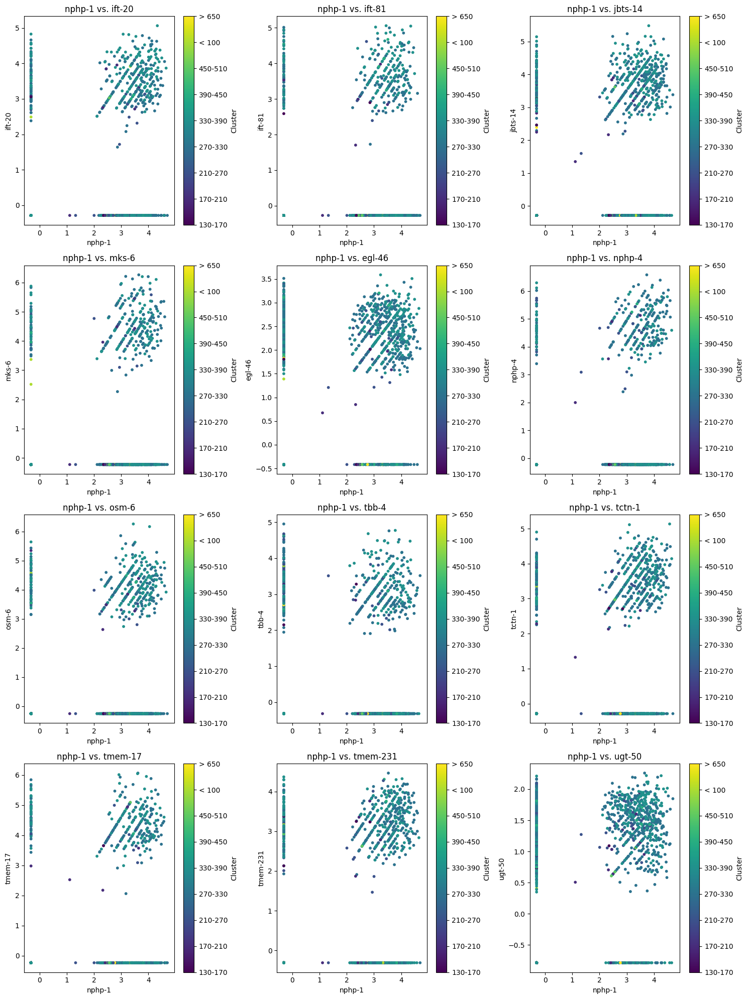

In [49]:
new_compare_genes_nphp1 = [
    'ift-20', 'ift-81', 'jbts-14', 'mks-6', 'egl-46', 'nphp-4', 
    'osm-6', 'tbb-4', 'tctn-1', 'tmem-17', 'tmem-231', 'ugt-50'
]

num_new_plots = len(new_compare_genes_nphp1)
cols_new = 3
rows_new = (num_new_plots + cols_new - 1) // cols_new

fig, axes = plt.subplots(nrows=rows_new, ncols=cols_new, figsize=(15, 5 * rows_new))
axes = axes.flatten()

# Create a color map and norm to handle the coloring and labeling of clusters
cluster_names = band1_data['cluster'].astype('category').cat.categories
cmap = plt.cm.viridis  # Using the viridis color map
norm = plt.Normalize(vmin=0, vmax=len(cluster_names)-1)

for i, gene_y in enumerate(new_compare_genes_nphp1):
    if 'nphp-1' in band1_data.columns and gene_y in band1_data.columns:
        sc = axes[i].scatter(band1_data['nphp-1'], band1_data[gene_y],
                             c=band1_data['cluster'].astype('category').cat.codes, cmap=cmap, norm=norm, s=10)
        axes[i].set_title(f'nphp-1 vs. {gene_y}')
        axes[i].set_xlabel('nphp-1')
        axes[i].set_ylabel(gene_y)

        # Create a color bar with actual cluster names
        cbar = fig.colorbar(sc, ax=axes[i], ticks=np.arange(len(cluster_names)))
        cbar.set_label('Cluster')
        cbar.set_ticklabels(cluster_names)

    else:
        axes[i].set_visible(False)  # Hide unused axes

plt.tight_layout()
plt.show()

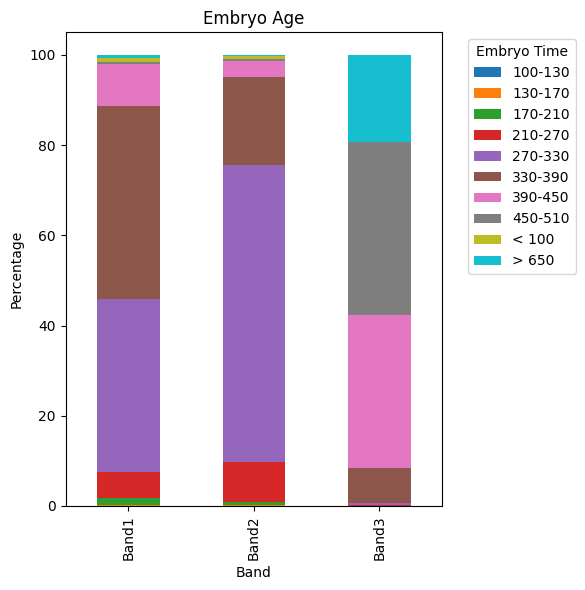

In [6]:
# Filter data for only Band1, Band2, and Band3
filtered_df = filtered_data[filtered_data['band'].isin(['Band1', 'Band2', 'Band3'])]

import matplotlib.pyplot as plt
import seaborn as sns

# create a pivot table to count occurrences of each cluster in each band
pivot_table = filtered_df.pivot_table(index='band', columns='cluster', aggfunc='size', fill_value=0)
pivot_table_percentage = pivot_table.div(pivot_table.sum(axis=1), axis=0) * 100

# Plot the stacked bar chart with percentages
pivot_table_percentage.plot(kind='bar', stacked=True, figsize=(6, 6))

plt.title('Embryo Age')
plt.xlabel('Band')
plt.ylabel('Percentage')
plt.legend(title='Embryo Time', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Show the plot
plt.show()

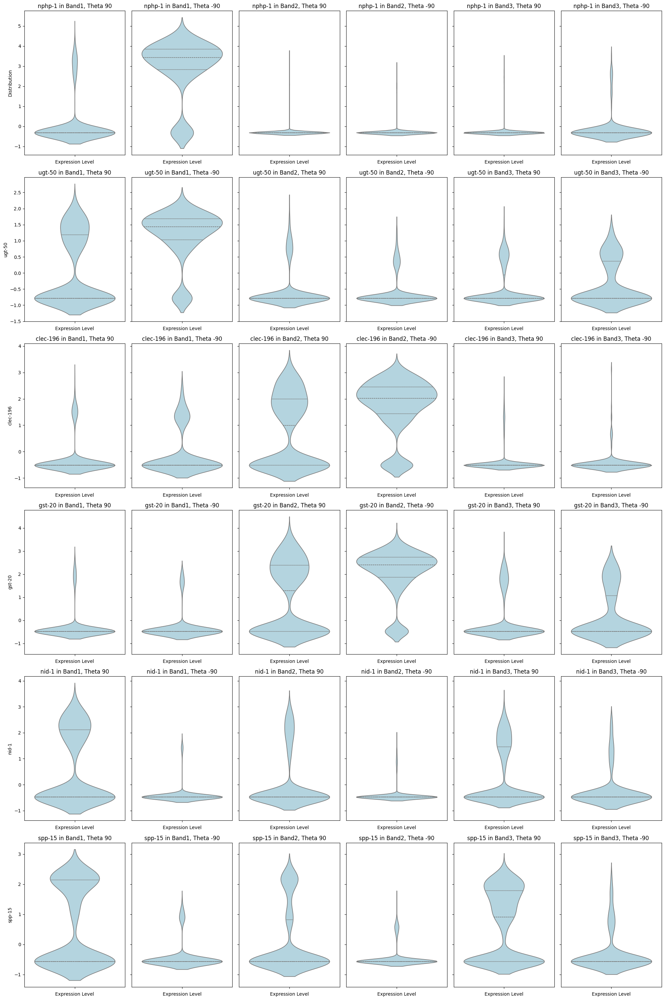

In [75]:
# Filter cells at the poles
poles_data = combined_data[combined_data['latitude'].isin([90, -90])]

# Create 6 groups based on Band and Theta
groups = {}
for band in ['Band1', 'Band2', 'Band3']:
    for theta in [90, -90]:
        group_key = f'{band}, Theta {theta}'
        groups[group_key] = poles_data[(poles_data['band'] == band) & (poles_data['latitude'] == theta)]

# Setting up the plot
fig, axes = plt.subplots(nrows=len(genes), ncols=6, figsize=(20, 5 * len(genes)), sharey='row')

# Plotting violin plots for each gene in each group
for i, gene in enumerate(genes):
    if gene in combined_data.columns:
        for j, (group_key, group_data) in enumerate(groups.items()):
            if gene in group_data.columns:
                sns.violinplot(y=group_data[gene], ax=axes[i, j], inner='quartile', color='lightblue')
                axes[i, j].set_title(f'{gene} in {group_key}')
                axes[i, j].set_xlabel('Expression Level')
            else:
                axes[i, j].text(0.5, 0.5, 'Data not available', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)
    else:
        for j in range(6):
            axes[i, j].text(0.5, 0.5, f'{gene} not in dataset', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)

    # Set y-axis label only for the first column
    if i == 0:
        axes[i, 0].set_ylabel('Distribution')

plt.tight_layout()
plt.show()


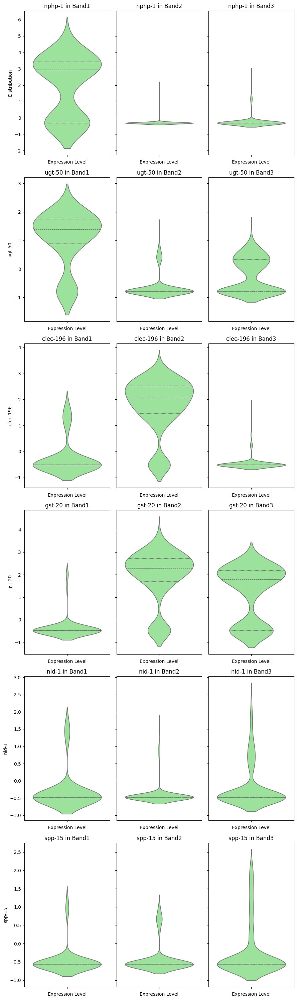

In [77]:
original_band_data = combined_data[~combined_data['latitude'].isin([90, -90])]

# Setting up the plot for the original bands with internal latitudes
fig, axes = plt.subplots(nrows=len(genes), ncols=3, figsize=(9, 5 * len(genes)), sharey='row')

# Plotting violin plots for each gene across the original three bands
for i, gene in enumerate(genes):
    if gene in original_band_data.columns:
        for j, band in enumerate(['Band1', 'Band2', 'Band3']):
            band_data = original_band_data[original_band_data['band'] == band]
            if gene in band_data.columns:
                sns.violinplot(y=band_data[gene], ax=axes[i, j], inner='quartile', color='lightgreen')
                axes[i, j].set_title(f'{gene} in {band}')
                axes[i, j].set_xlabel('Expression Level')
            else:
                axes[i, j].text(0.5, 0.5, 'Data not available', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)
    else:
        for j in range(3):
            axes[i, j].text(0.5, 0.5, f'{gene} not in dataset', horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)

    # Set y-axis label only for the first column
    if i == 0:
        axes[i, 0].set_ylabel('Distribution')

plt.tight_layout()
plt.show()

In [78]:
all_band_genes

{'C03C10.5',
 'C03C10.9',
 'C04A11.2',
 'C08F1.11',
 'C14F11.6',
 'C17E4.1',
 'C17E4.19',
 'C29F5.1',
 'C34E7.4',
 'C47E12.13',
 'D1086.12',
 'E01G4.5',
 'F21H7.3',
 'F37H8.5',
 'F48D6.4',
 'F48E3.9',
 'F58H10.1',
 'K02B12.2',
 'K07E3.4',
 'K08B4.2',
 'K10G6.4',
 'M01D1.12',
 'R01H2.8',
 'R07E5.17',
 'T21B6.3',
 'W04H10.6',
 'Y37D8A.16',
 'Y41D4B.26',
 'Y57A10A.23',
 'ZK822.1',
 'bbs-9',
 'ceh-37',
 'che-13',
 'cht-1',
 'clec-196',
 'cpl-1',
 'csq-1',
 'ctg-1',
 'cutl-2',
 'daf-10',
 'dao-2',
 'dod-6',
 'dpy-10',
 'dpy-17',
 'dsl-3',
 'dyf-7',
 'egl-46',
 'fbn-1',
 'fbxb-18',
 'fbxb-19',
 'fbxb-70',
 'fbxc-20',
 'fbxc-24',
 'fkb-7',
 'glb-1',
 'gsnl-1',
 'gst-20',
 'hch-1',
 'ift-20',
 'ift-81',
 'jbts-14',
 'lbp-2',
 'lec-5',
 'lec-9',
 'let-2',
 'lgc-34',
 'lpr-3',
 'mig-18',
 'mig-6',
 'mks-6',
 'mksr-2',
 'mlt-11',
 'mnp-1',
 'mup-2',
 'nid-1',
 'nlp-31',
 'noah-1',
 'noah-2',
 'nphp-1',
 'nphp-4',
 'osm-6',
 'pck-1',
 'pmt-2',
 'qdpr-1',
 'sams-1',
 'spp-10',
 'spp-15',
 'tbb-4',
